## Objetivo desta Fase
Neste segundo estágio do projeto, é realizado transição da **Engenharia de Dados Distribuída (PySpark)** para o ambiente de **Ciência de Dados e Modelagem Preditiva (Pandas / Scikit-Learn)**. 

Este notebook tem como propósito:

1. **Análise Exploratória de Dados (EDA) Orientada a Evidências:** Investigar empiricamente o comportamento estatístico das variáveis na *Analytical Base Table (ABT)*, diagnosticando assimetrias, *outliers*, volumetria de nulos legítimos, multicolinearidade e poder discriminante frente ao risco de inadimplência (`TARGET`).
2. **Seleção de Variáveis e Definição de Contrato:** Eleger, sob justificativa estatística e de negócio bancário, um subconjunto enxuto de **10 a 15 variáveis** que comporão o *schema* de entrada da futura API de inferência em tempo real.
3. **Arquitetura de Pipeline Anti-Leakage:** Construir um pipeline único e reprodutível (`Pipeline` + `ColumnTransformer`) garantindo que todas as estatísticas de imputação e escalonamento sejam aprendidas estritamente no conjunto de treino.
4. **Avaliação de Risco de Crédito e Calibração:** Avaliar a capacidade de ordenação de risco do modelo através de métricas padrão da indústria financeira (**ROC-AUC** e **Estatística KS**) e calibrar matematicamente o limiar de decisão (*threshold*) na base de validação.
5. **Serialização e Governança (MLOps):** Exportar o pipeline unificado (`.joblib`) e suas métricas oficiais (`.json`), validando a integridade do artefato para implantação em produção.


---
# 1. Bibliotecas Utilizadas

In [1]:
import warnings
import pandas as pd
import numpy as np
import os
import time
import sys
import subprocess
import json
import joblib
from scipy import stats
from pathlib import Path
from datetime import datetime

import matplotlib.pyplot as plt
import seaborn as sns

from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    roc_curve, roc_auc_score, precision_recall_curve, fbeta_score,
    f1_score, recall_score, precision_score, confusion_matrix,
    classification_report, make_scorer
)

---
# 2. Configurações Globais

In [2]:
# Evitar avisos
warnings.filterwarnings("ignore")

In [3]:
# Exibição e estética visual
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

--- 
# 3. Carregando os dados e EDA

In [4]:
# RESOLUÇÃO DE CAMINHOS RELATIVOS E CRIAÇÃO DE DIRETÓRIOS DE SAÍDA

# Detecta se o notebook está rodando de dentro de 'notebooks/' ou da raiz do projeto
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR

DATA_GOLD_PATH = PROJECT_ROOT / "data" / "gold" / "abt_credit_risk.parquet"
# Contigencia caso o parquet tenha sido salvo em outro local
if not DATA_GOLD_PATH.exists():
    DATA_GOLD_PATH = CURRENT_DIR / "data" / "gold" / "abt_credit_risk.parquet"

OUTPUTS_DIR = PROJECT_ROOT / "outputs"
MODELS_DIR = PROJECT_ROOT / "models"

OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

In [5]:
# LEITURA DA ABT (CAMADA GOLD) E VALIDAÇÃO DE INTEGRIDADE

if not DATA_GOLD_PATH.exists():
    raise FileNotFoundError(f"Arquivo Parquet não encontrado em: {DATA_GOLD_PATH}")

df_abt = pd.read_parquet(DATA_GOLD_PATH)

print("=" * 80)
print("RESUMO ESTRUTURAL DA ANALYTICAL BASE TABLE (GOLD)")
print("=" * 80)
print(f"Dimensões da Base : {df_abt.shape[0]:,} linhas x {df_abt.shape[1]} colunas")
print(f"Uso de Memória RAM: {df_abt.memory_usage(deep=True).sum() / (1024**2):.2f} MB")
print(f"IDs Únicos        : {df_abt['SK_ID_CURR'].nunique():,} (Chave Primária íntegra: {df_abt['SK_ID_CURR'].is_unique})")
print("-" * 80)

# Tabela de diagnóstico rápido de tipos e valores ausentes
schema_summary = pd.DataFrame({
    "Tipo (Dtype)": df_abt.dtypes,
    "Nulos (Qtd)": df_abt.isnull().sum(),
    "Nulos (%)": (df_abt.isnull().mean() * 100).round(2),
    "Valores Únicos": df_abt.nunique()
})
display(schema_summary)

print("\nAmostra dos 5 primeiros registros:")
display(df_abt.head())

RESUMO ESTRUTURAL DA ANALYTICAL BASE TABLE (GOLD)
Dimensões da Base : 307,511 linhas x 20 colunas
Uso de Memória RAM: 76.85 MB
IDs Únicos        : 307,511 (Chave Primária íntegra: True)
--------------------------------------------------------------------------------


,Tipo (Dtype),Nulos (Qtd),Nulos (%),Valores Únicos
SK_ID_CURR,int32,0,0.0000,307511
TARGET,int32,0,0.0000,2
AMT_INCOME_TOTAL,float64,0,0.0000,2548
AMT_CREDIT,float64,0,0.0000,5603
AMT_ANNUITY,float64,12,0.0000,13672
AMT_GOODS_PRICE,float64,278,0.0900,1002
AGE_YEARS,float64,0,0.0000,17460
YEARS_EMPLOYED,float64,55374,18.0100,12573
FLAG_OWN_CAR,int32,0,0.0000,2
FLAG_OWN_REALTY,int32,0,0.0000,2



Amostra dos 5 primeiros registros:


,SK_ID_CURR,TARGET,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,AGE_YEARS,YEARS_EMPLOYED,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,EXT_SOURCE_2,EXT_SOURCE_3,BUREAU_TOTAL_LOANS,BUREAU_ACTIVE_LOANS,BUREAU_TOTAL_CREDIT_SUM,BUREAU_TOTAL_CREDIT_DEBT,DTI_RATIO,CREDIT_INCOME_RATIO
0,100039,0,"360,000.0000","733,315.5000","39,069.0000","679,500.0000",32.0164,5.6400,1,0,Commercial associate,Secondary / secondary special,0.3217,0.4118,9,3,"4,489,092.0000","2,438,748.0000",0.1085,2.0370
1,100056,0,"360,000.0000","1,506,816.0000","49,927.5000","1,350,000.0000",50.0041,26.0726,1,1,Working,Secondary / secondary special,0.5239,NaN,0,0,0.0000,0.0000,0.1387,4.1856
2,100112,1,"315,000.0000","953,460.0000","64,107.0000","900,000.0000",27.9233,5.5168,1,1,Commercial associate,Incomplete higher,0.4323,0.0775,2,2,"130,500.0000","85,648.5000",0.2035,3.0269
3,100118,0,"90,000.0000","675,000.0000","26,541.0000","675,000.0000",61.5222,NaN,0,1,Pensioner,Secondary / secondary special,0.6263,NaN,0,0,0.0000,0.0000,0.2949,7.5000
4,100137,0,"225,000.0000","891,072.0000","45,625.5000","720,000.0000",55.5346,NaN,1,1,Pensioner,Secondary / secondary special,0.0867,NaN,0,0,0.0000,0.0000,0.2028,3.9603


## 3.1 Inspeção da Variável Alvo (`TARGET`)


ANÁLISE DE DISTRIBUIÇÃO DA VARIÁVEL ALVO (TARGET)


,Status do Contrato,Contagem Absoluta,Proporção (%)
0,0 - Adimplente (Bom Pagador),282686,91.9300
1,1 - Inadimplente (Default),24825,8.0700


-> Razão de Desbalanceamento (Adimplentes : Inadimplentes) = 11.39 : 1
-> Taxa Base de Inadimplência da Carteira (Bad Rate)       = 8.07%


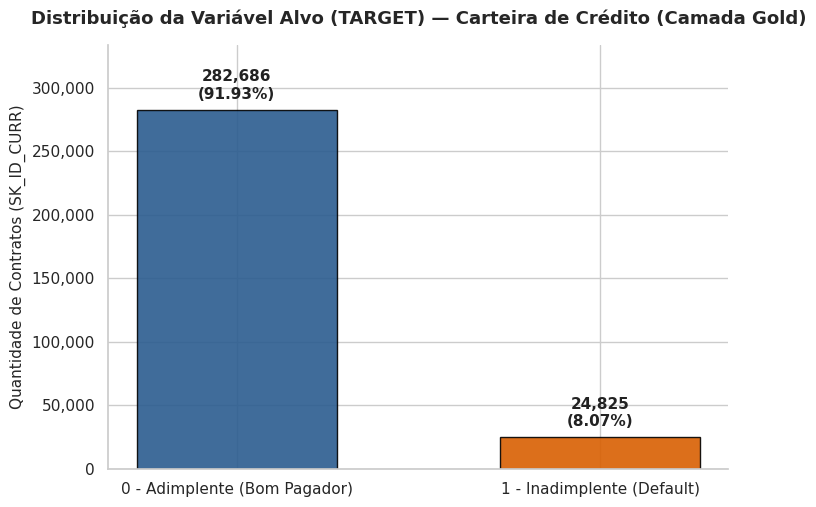

In [6]:
# INSPEÇÃO ESTATÍSTICA E VISUAL DA VARIÁVEL ALVO (TARGET)
target_counts = df_abt["TARGET"].value_counts().sort_index()
target_props = df_abt["TARGET"].value_counts(normalize=True).sort_index() * 100

df_target_stats = pd.DataFrame({
    "Status do Contrato": ["0 - Adimplente (Bom Pagador)", "1 - Inadimplente (Default)"],
    "Contagem Absoluta": target_counts.values,
    "Proporção (%)": target_props.values.round(2)
})

imbalance_ratio = target_counts[0] / target_counts[1]

print("\n" + "=" * 80)
print("ANÁLISE DE DISTRIBUIÇÃO DA VARIÁVEL ALVO (TARGET)")
print("=" * 80)
display(df_target_stats)
print(f"-> Razão de Desbalanceamento (Adimplentes : Inadimplentes) = {imbalance_ratio:.2f} : 1")
print(f"-> Taxa Base de Inadimplência da Carteira (Bad Rate)       = {target_props[1]:.2f}%")

# Construção do Gráfico de Distribuição do TARGET
fig, ax = plt.subplots(figsize=(8, 5.5))
colors = ["#2b5c8f", "#d95f02"]  

bars = ax.bar(
    df_target_stats["Status do Contrato"],
    df_target_stats["Contagem Absoluta"],
    color=colors,
    width=0.55,
    edgecolor="black",
    alpha=0.9
)

for bar, count, pct in zip(bars, df_target_stats["Contagem Absoluta"], df_target_stats["Proporção (%)"]):
    height = bar.get_height()
    ax.annotate(
        f"{count:,}\n({pct:.2f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color="#222222"
    )

ax.set_title("Distribuição da Variável Alvo (TARGET) — Carteira de Crédito (Camada Gold)", fontsize=13, fontweight="bold", pad=15)
ax.set_ylabel("Quantidade de Contratos (SK_ID_CURR)", fontsize=11)
ax.set_ylim(0, target_counts.max() * 1.18)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x):,}"))
sns.despine(top=True, right=True)

target_plot_path = OUTPUTS_DIR / "01_distribicao_target.png"
plt.savefig(target_plot_path, dpi=300, bbox_inches="tight")
plt.show()

## A inspeção estrutural e estatística da *Analytical Base Table (ABT)* explicita três fatos fundamentais que guiarão a arquitetura do pipeline preditivo:

1. **Qualidade e Granularidade da ABT:** A tabela mantém exatamente **307.511 registros únicos** (`SK_ID_CURR` íntegro e sem duplicações pós-*join* 1:N com o Bureau). As variáveis agregadas do Bureau (`BUREAU_*`) apresentam `0.00%` de nulos.
2. **Mapeamento de Nulos Legítimos de Negócio:** 
   - `YEARS_EMPLOYED` apresenta **18,01% (55.374)** de valores ausentes, resultantes da alteração do sentinela `365243` (associado a pensionistas/aposentados sem vínculo laboral formal).
   - `EXT_SOURCE_3` (**19,83%**) e `EXT_SOURCE_2` (**0,21%**) possuem ausências naturais decorrentes de clientes sem histórico de crédito registrado naqueles birôs externos (*no-hit*).
   - `AMT_GOODS_PRICE` (**0,09%** / 278 registros) e `AMT_ANNUITY` / `DTI_RATIO` (**12 registros**) possuem ausências residuais.
   - **Implicação Arquitetural:** Modelos lineares e transformadores padrão do Scikit-Learn não operam nativamente com `NaN`. Será mandatória a inclusão de uma etapa de **Imputação Estatística** dentro do `ColumnTransformer` (calculada estritamente na partição de treino para evitar *Data Leakage*).
3. **Comprovação de Desbalanceamento Severo (`TARGET`):**
   - **Adimplentes (`0`):** 282.686 contratos (**91,93%**)
   - **Inadimplentes (`1`):** 24.825 contratos (**8,07%** — *Bad Rate* da carteira)
   - **Razão de Desbalanceamento:** **11,39 : 1**
   - **Implicação Arquitetural:** Fica invalidado o uso da *Acurácia* como métrica de avaliação (um classificador nulo atingiria 91,93% de acerto aprovando toda a carteira). Fica empiricamente justificada a obrigatoriedade de: (a) divisão de dados estratificada (`stratify=y`), (b) ponderação de classes inversamente proporcional à frequência (`class_weight='balanced'`), e (c) avaliação baseada em ordenação de risco (**ROC-AUC** e **Estatística KS**) seguida de calibração de *threshold* para otimização do *trade-off* entre Precisão e Recall.



## 3.2: Análise Bivariada, Correlações e Diagnóstico de Outliers/Assimetria

In [7]:
# DIAGNÓSTICO ESTATÍSTICO DE DISTRIBUIÇÃO, ASSIMETRIA E OUTLIERS

numeric_cols = [
    "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE",
    "DTI_RATIO", "CREDIT_INCOME_RATIO", "AGE_YEARS", "YEARS_EMPLOYED",
    "EXT_SOURCE_2", "EXT_SOURCE_3", "BUREAU_TOTAL_LOANS", "BUREAU_ACTIVE_LOANS",
    "BUREAU_TOTAL_CREDIT_SUM", "BUREAU_TOTAL_CREDIT_DEBT"
]
binary_cols = ["FLAG_OWN_CAR", "FLAG_OWN_REALTY"]
categorical_cols = ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE"]

print("=" * 95)
print("ESTATÍSTICAS DESCRITIVAS, QUANTIS E ASSIMETRIA (VARIÁVEIS NUMÉRICAS CONTÍNUAS)")
print("=" * 95)
desc_stats = df_abt[numeric_cols].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T
desc_stats["skewness"] = df_abt[numeric_cols].skew()
desc_stats["null_pct"] = (df_abt[numeric_cols].isnull().mean() * 100).round(2)

cols_order = ["count", "null_pct", "mean", "std", "min", "25%", "50%", "75%", "95%", "99%", "max", "skewness"]
display(desc_stats[cols_order])

# Comparação de Medianas e Médias 
print("\n" + "=" * 95)
print("COMPARAÇÃO DE MEDIANAS E MÉDIAS POR CLASSE DO TARGET (0 = ADIMPLENTE | 1 = INADIMPLENTE)")
print("=" * 95)
grouped_medians = df_abt.groupby("TARGET")[numeric_cols].median().T
grouped_medians.columns = ["Mediana (Target=0)", "Mediana (Target=1)"]
grouped_means = df_abt.groupby("TARGET")[numeric_cols].mean().T
grouped_means.columns = ["Média (Target=0)", "Média (Target=1)"]

bivariate_num_summary = pd.concat([grouped_medians, grouped_means], axis=1)
bivariate_num_summary["Diff Mediana (%)"] = (
    (bivariate_num_summary["Mediana (Target=1)"] - bivariate_num_summary["Mediana (Target=0)"])
    / bivariate_num_summary["Mediana (Target=0)"].replace(0, np.nan) * 100
).round(2)
display(bivariate_num_summary)

ESTATÍSTICAS DESCRITIVAS, QUANTIS E ASSIMETRIA (VARIÁVEIS NUMÉRICAS CONTÍNUAS)


,count,null_pct,mean,std,min,25%,50%,75%,95%,99%,max,skewness
AMT_INCOME_TOTAL,"307,511.0000",0.0000,"168,797.9193","237,123.1463","25,650.0000","112,500.0000","147,150.0000","202,500.0000","337,500.0000","472,500.0000","117,000,000.0000",391.5597
AMT_CREDIT,"307,511.0000",0.0000,"599,025.9997","402,490.7770","45,000.0000","270,000.0000","513,531.0000","808,650.0000","1,350,000.0000","1,854,000.0000","4,050,000.0000",1.2348
AMT_ANNUITY,"307,499.0000",0.0000,"27,108.5739","14,493.7373","1,615.5000","16,524.0000","24,903.0000","34,596.0000","53,325.0000","70,006.5000","258,025.5000",1.5798
AMT_GOODS_PRICE,"307,233.0000",0.0900,"538,396.2074","369,446.4605","40,500.0000","238,500.0000","450,000.0000","679,500.0000","1,305,000.0000","1,800,000.0000","4,050,000.0000",1.3490
DTI_RATIO,"307,499.0000",0.0000,0.1809,0.0946,0.0002,0.1148,0.1628,0.2291,0.3547,0.4835,1.8760,1.5120
CREDIT_INCOME_RATIO,"307,511.0000",0.0000,3.9576,2.6897,0.0048,2.0187,3.2651,5.1599,9.1567,13.0273,84.7368,1.8360
AGE_YEARS,"307,511.0000",0.0000,43.9069,11.9479,20.5038,33.9849,43.1211,53.8864,63.5291,66.8556,69.0732,0.1157
YEARS_EMPLOYED,"252,137.0000",18.0100,6.5275,6.4021,0.0000,2.0999,4.5120,8.6927,19.9617,31.0425,49.0404,1.9683
EXT_SOURCE_2,"306,851.0000",0.2100,0.5144,0.1911,0.0000,0.3925,0.5660,0.6636,0.7477,0.7828,0.8550,-0.7936
EXT_SOURCE_3,"246,546.0000",19.8300,0.5109,0.1948,0.0005,0.3706,0.5353,0.6691,0.7863,0.8328,0.8960,-0.4094



COMPARAÇÃO DE MEDIANAS E MÉDIAS POR CLASSE DO TARGET (0 = ADIMPLENTE | 1 = INADIMPLENTE)


,Mediana (Target=0),Mediana (Target=1),Média (Target=0),Média (Target=1),Diff Mediana (%)
AMT_INCOME_TOTAL,"148,500.0000","135,000.0000","169,077.7223","165,611.7609",-9.0900
AMT_CREDIT,"517,788.0000","497,520.0000","602,648.2820","557,778.5277",-3.9100
AMT_ANNUITY,"24,876.0000","25,263.0000","27,163.6233","26,481.7443",1.5600
AMT_GOODS_PRICE,"450,000.0000","450,000.0000","542,736.7950","488,972.4126",0.0000
DTI_RATIO,0.1623,0.1693,0.1805,0.1855,4.3100
CREDIT_INCOME_RATIO,3.2667,3.2531,3.9637,3.8874,-0.4100
AGE_YEARS,43.4689,39.1020,44.1839,40.7524,-10.0500
YEARS_EMPLOYED,4.6297,3.3676,6.6753,4.9690,-27.2600
EXT_SOURCE_2,0.5739,0.4404,0.5235,0.4109,-23.2700
EXT_SOURCE_3,0.5460,0.3791,0.5210,0.3907,-30.5700


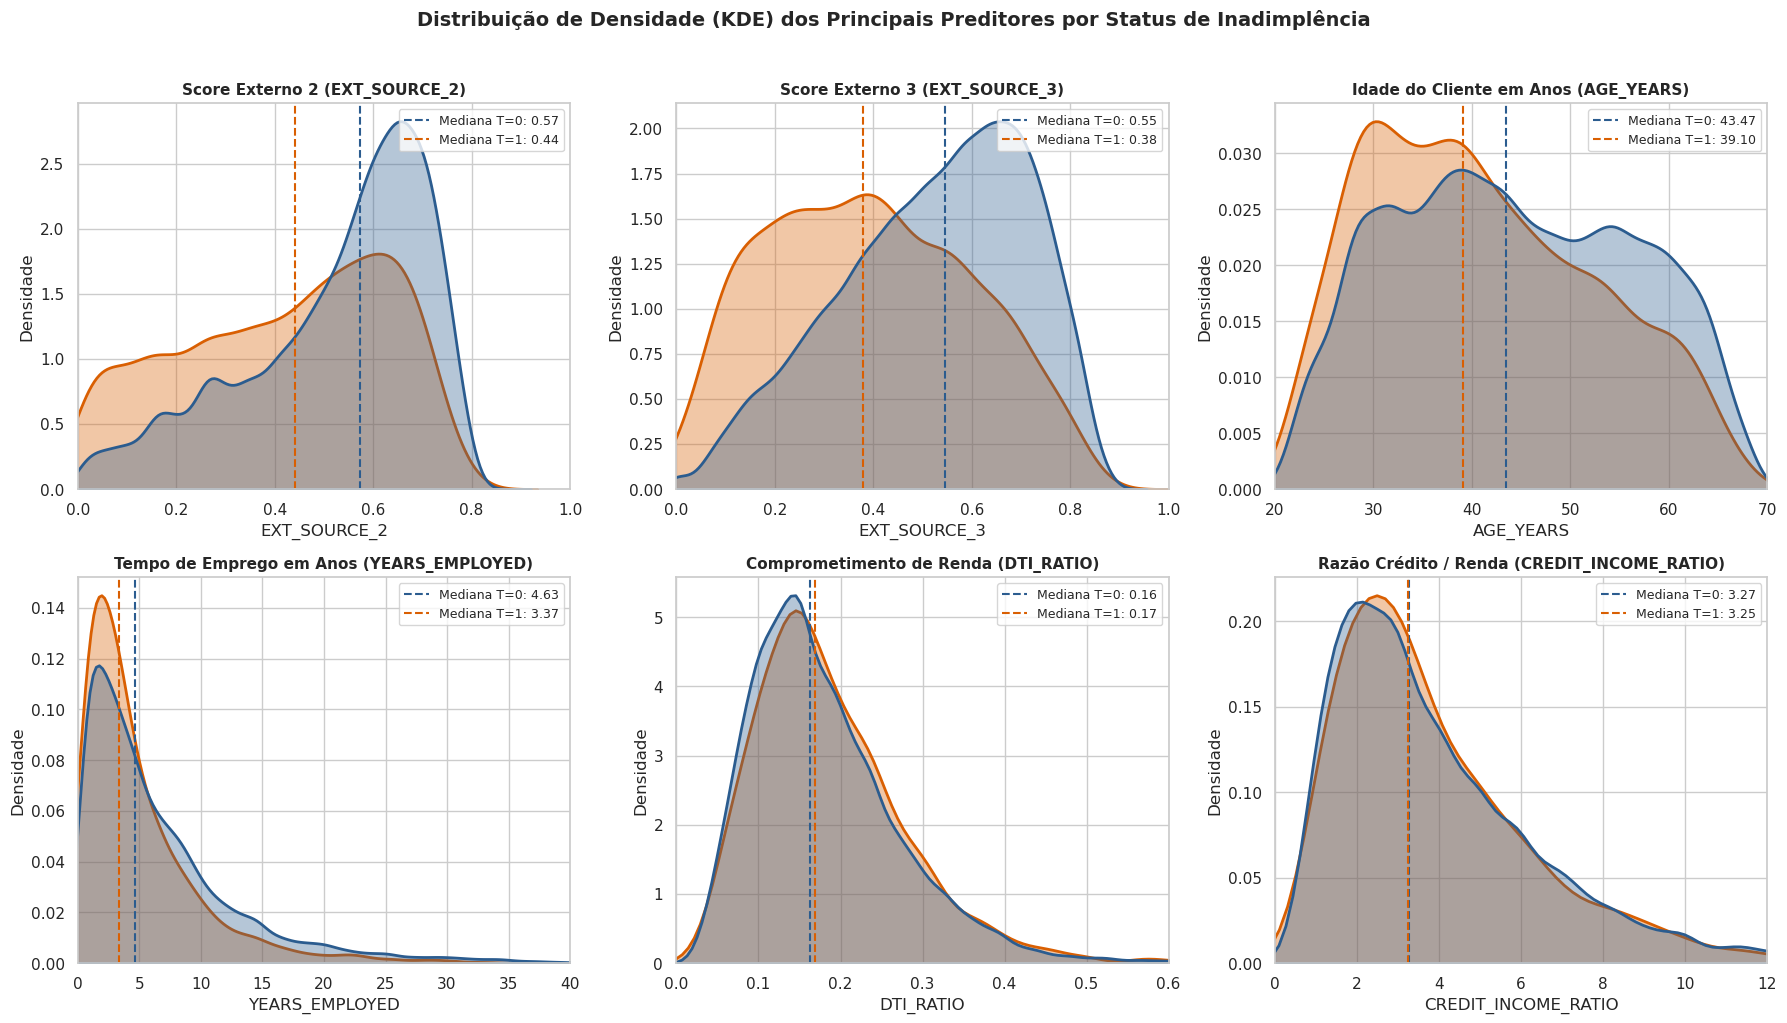

In [8]:
#  VISUAL BIVARIADO: PREDITORES NUMÉRICOS CHAVE VS TARGET (KDE PLOT)

key_plot_features = [
    ("EXT_SOURCE_2", "Score Externo 2 (EXT_SOURCE_2)", (0, 1)),
    ("EXT_SOURCE_3", "Score Externo 3 (EXT_SOURCE_3)", (0, 1)),
    ("AGE_YEARS", "Idade do Cliente em Anos (AGE_YEARS)", (20, 70)),
    ("YEARS_EMPLOYED", "Tempo de Emprego em Anos (YEARS_EMPLOYED)", (0, 40)),
    ("DTI_RATIO", "Comprometimento de Renda (DTI_RATIO)", (0, 0.60)),
    ("CREDIT_INCOME_RATIO", "Razão Crédito / Renda (CREDIT_INCOME_RATIO)", (0, 12))
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# Amostra estratificada de 50k registros apenas para renderização rápida  KDE
df_sample_plot = df_abt.sample(n=min(50000, len(df_abt)), random_state=42)

for idx, (col, title, xlim) in enumerate(key_plot_features):
    ax = axes[idx]
    sns.kdeplot(
        data=df_sample_plot, x=col, hue="TARGET",
        common_norm=False, fill=True, palette={0: "#2b5c8f", 1: "#d95f02"},
        alpha=0.35, linewidth=2, ax=ax
    )
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlim(xlim)
    ax.set_ylabel("Densidade")
    
    # Adiciona linhas verticais de mediana na base completa
    med_0 = df_abt.loc[df_abt["TARGET"] == 0, col].median()
    med_1 = df_abt.loc[df_abt["TARGET"] == 1, col].median()
    ax.axvline(med_0, color="#2b5c8f", linestyle="--", linewidth=1.5, label=f"Mediana T=0: {med_0:.2f}")
    ax.axvline(med_1, color="#d95f02", linestyle="--", linewidth=1.5, label=f"Mediana T=1: {med_1:.2f}")
    ax.legend(fontsize=9, loc="upper right")

plt.suptitle("Distribuição de Densidade (KDE) dos Principais Preditores por Status de Inadimplência", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

bivar_num_path = OUTPUTS_DIR / "02_distribuicao_numerica_vs_target.png"
plt.savefig(bivar_num_path, dpi=300, bbox_inches="tight")
plt.show()

ANÁLISE DE TAXA DE INADIMPLÊNCIA (BAD RATE) POR VARIÁVEL CATEGÓRICA E BINÁRIA

-> Variável: NAME_INCOME_TYPE


,NAME_INCOME_TYPE,Contratos,Inadimplentes,Bad_Rate_Pct,Participação Carteira (%),Risco Relativo (Lift)
2,Maternity leave,5,2,40.0000,0.0000,4.9500
6,Unemployed,22,8,36.3600,0.0100,4.5000
7,Working,158774,15224,9.5900,51.6300,1.1900
1,Commercial associate,71617,5360,7.4800,23.2900,0.9300
4,State servant,21703,1249,5.7500,7.0600,0.7100
3,Pensioner,55362,2982,5.3900,18.0000,0.6700
0,Businessman,10,0,0.0000,0.0000,0.0000
5,Student,18,0,0.0000,0.0100,0.0000



-> Variável: NAME_EDUCATION_TYPE


,NAME_EDUCATION_TYPE,Contratos,Inadimplentes,Bad_Rate_Pct,Participação Carteira (%),Risco Relativo (Lift)
3,Lower secondary,3816,417,10.9300,1.2400,1.3500
4,Secondary / secondary special,218391,19524,8.9400,71.0200,1.1100
2,Incomplete higher,10277,872,8.4800,3.3400,1.0500
1,Higher education,74863,4009,5.3600,24.3400,0.6600
0,Academic degree,164,3,1.8300,0.0500,0.2300



-> Variável: FLAG_OWN_CAR


,FLAG_OWN_CAR,Contratos,Inadimplentes,Bad_Rate_Pct,Participação Carteira (%),Risco Relativo (Lift)
0,0,202924,17249,8.5000,65.9900,1.0500
1,1,104587,7576,7.2400,34.0100,0.9000



-> Variável: FLAG_OWN_REALTY


,FLAG_OWN_REALTY,Contratos,Inadimplentes,Bad_Rate_Pct,Participação Carteira (%),Risco Relativo (Lift)
0,0,94199,7842,8.3200,30.6300,1.0300
1,1,213312,16983,7.9600,69.3700,0.9900


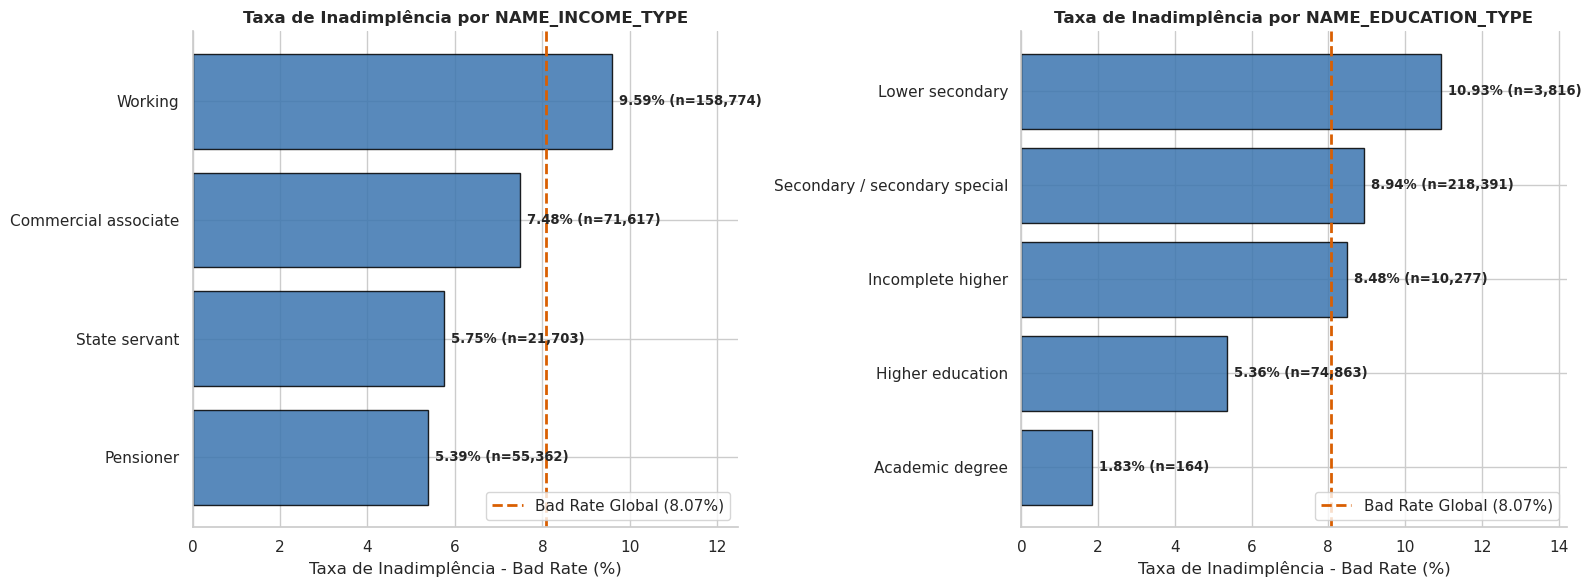

In [9]:
# ANÁLISE BIVARIADA DE VARIÁVEIS CATEGÓRICAS E FLAGS BINÁRIAS (BAD RATE)
print("=" * 95)
print("ANÁLISE DE TAXA DE INADIMPLÊNCIA (BAD RATE) POR VARIÁVEL CATEGÓRICA E BINÁRIA")
print("=" * 95)

global_bad_rate = df_abt["TARGET"].mean() * 100

for col in categorical_cols + binary_cols:
    cat_summary = df_abt.groupby(col).agg(
        Contratos=("TARGET", "count"),
        Inadimplentes=("TARGET", "sum"),
        Bad_Rate_Pct=("TARGET", lambda x: round(x.mean() * 100, 2))
    ).reset_index()
    cat_summary["Participação Carteira (%)"] = (cat_summary["Contratos"] / len(df_abt) * 100).round(2)
    cat_summary["Risco Relativo (Lift)"] = (cat_summary["Bad_Rate_Pct"] / global_bad_rate).round(2)
    cat_summary = cat_summary.sort_values(by="Bad_Rate_Pct", ascending=False)
    print(f"\n-> Variável: {col}")
    display(cat_summary)

# Gráfico de Taxa de Inadimplência para as Categóricas principais
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, col in enumerate(categorical_cols):
    ax = axes[idx]
    # Filtrar categorias com pelo menos 100 contratos para evitar distorção visual de micro-categorias
    cat_stats = df_abt.groupby(col).filter(lambda g: len(g) >= 100).groupby(col)["TARGET"].agg(
        count="count", bad_rate=lambda x: x.mean() * 100
    ).sort_values(by="bad_rate", ascending=True).reset_index()
    
    bars = ax.barh(cat_stats[col], cat_stats["bad_rate"], color="#3b75af", edgecolor="black", alpha=0.85)
    ax.axvline(global_bad_rate, color="#d95f02", linestyle="--", linewidth=2, label=f"Bad Rate Global ({global_bad_rate:.2f}%)")
    
    for bar, count in zip(bars, cat_stats["count"]):
        width = bar.get_width()
        ax.annotate(
            f"{width:.2f}% (n={count:,})",
            xy=(width, bar.get_y() + bar.get_height() / 2),
            xytext=(5, 0), textcoords="offset points",
            ha="left", va="center", fontsize=9.5, fontweight="bold"
        )
    
    ax.set_title(f"Taxa de Inadimplência por {col}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Taxa de Inadimplência - Bad Rate (%)")
    ax.set_xlim(0, cat_stats["bad_rate"].max() * 1.30)
    ax.legend(loc="lower right")
    sns.despine(top=True, right=True)

plt.tight_layout()
cat_plot_path = OUTPUTS_DIR / "03_categórico_bad_rates.png"
plt.savefig(cat_plot_path, dpi=300, bbox_inches="tight")
plt.show()

RANKING DE CORRELAÇÃO LINEAR (PEARSON) COM A VARIÁVEL ALVO (TARGET)


,Correlação de Pearson com TARGET
EXT_SOURCE_3,-0.1789
EXT_SOURCE_2,-0.1605
AGE_YEARS,-0.0782
YEARS_EMPLOYED,-0.0750
BUREAU_ACTIVE_LOANS,0.0436
AMT_GOODS_PRICE,-0.0396
AMT_CREDIT,-0.0304
FLAG_OWN_CAR,-0.0219
BUREAU_TOTAL_CREDIT_SUM,-0.0180
DTI_RATIO,0.0143



PARES DE VARIÁVEIS EXPLICATIVAS COM ALTA CORRELAÇÃO (|r| >= 0.60 — Alerta de Multicolinearidade):


,Variável 1,Variável 2,Correlação (r)
1,AMT_CREDIT,AMT_GOODS_PRICE,0.9870
5,DTI_RATIO,CREDIT_INCOME_RATIO,0.7881
3,AMT_ANNUITY,AMT_GOODS_PRICE,0.7751
0,AMT_CREDIT,AMT_ANNUITY,0.7701
6,BUREAU_TOTAL_LOANS,BUREAU_ACTIVE_LOANS,0.7444
2,AMT_CREDIT,CREDIT_INCOME_RATIO,0.6511
4,AMT_GOODS_PRICE,CREDIT_INCOME_RATIO,0.6311


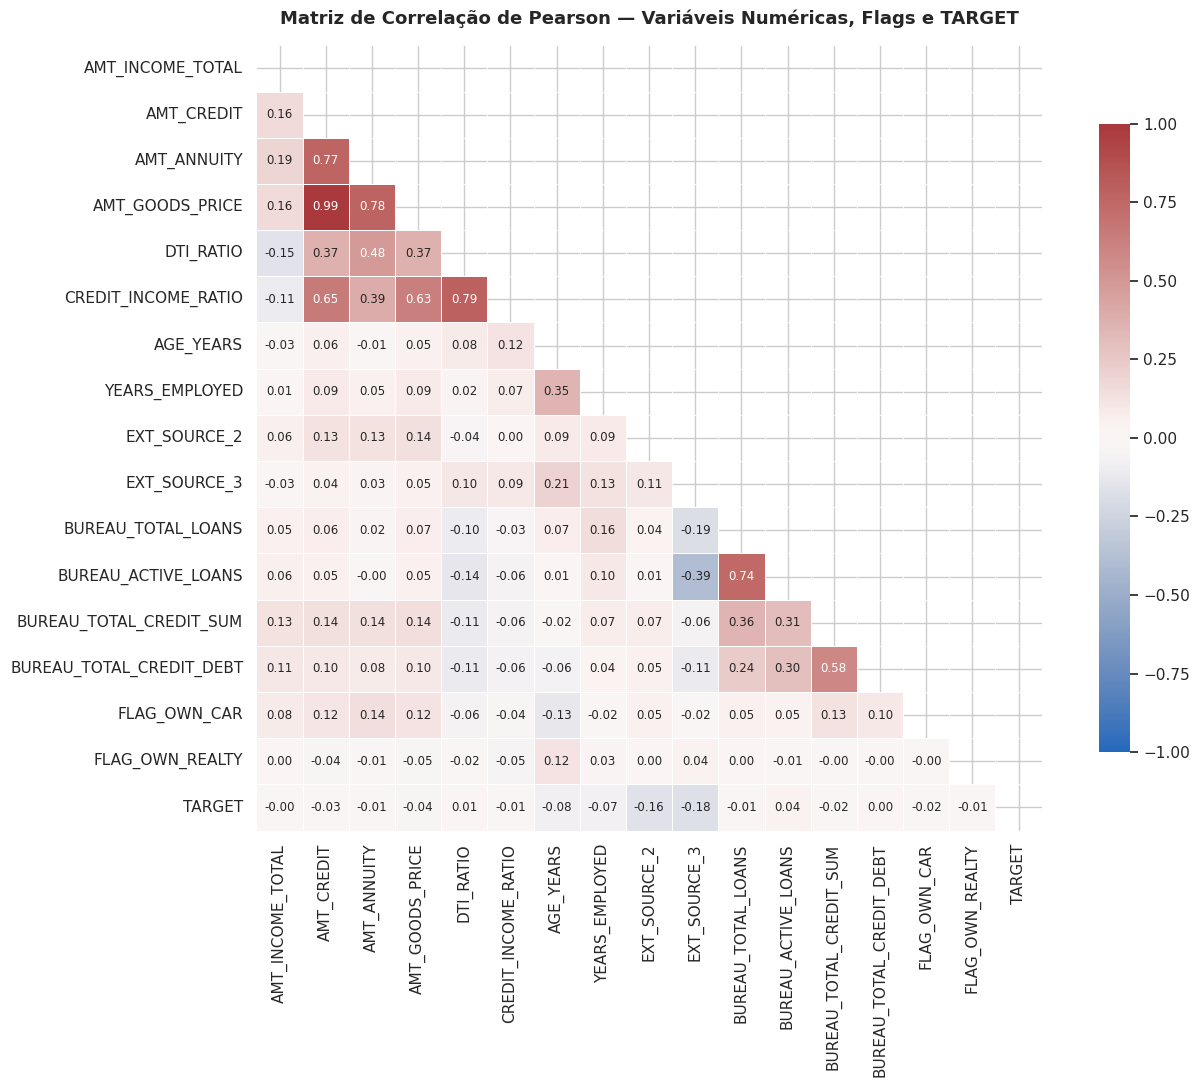

In [10]:
# MATRIZ DE CORRELAÇÃO E DIAGNÓSTICO DE MULTICOLINEARIDADE

corr_cols = numeric_cols + binary_cols + ["TARGET"]
corr_matrix = df_abt[corr_cols].corr(method="pearson")

print("=" * 95)
print("RANKING DE CORRELAÇÃO LINEAR (PEARSON) COM A VARIÁVEL ALVO (TARGET)")
print("=" * 95)
target_corr = corr_matrix["TARGET"].drop("TARGET").sort_values(key=abs, ascending=False).to_frame(name="Correlação de Pearson com TARGET")
display(target_corr)

# Identificar pares com alta colinearidade (|r| > 0.60) entre variáveis explicativas
print("\nPARES DE VARIÁVEIS EXPLICATIVAS COM ALTA CORRELAÇÃO (|r| >= 0.60 — Alerta de Multicolinearidade):")
high_corr_pairs = []
features_only_corr = df_abt[numeric_cols + binary_cols].corr()
for i in range(len(features_only_corr.columns)):
    for j in range(i + 1, len(features_only_corr.columns)):
        col1 = features_only_corr.columns[i]
        col2 = features_only_corr.columns[j]
        r_val = features_only_corr.iloc[i, j]
        if abs(r_val) >= 0.60:
            high_corr_pairs.append({"Variável 1": col1, "Variável 2": col2, "Correlação (r)": round(r_val, 4)})

df_high_corr = pd.DataFrame(high_corr_pairs).sort_values(by="Correlação (r)", key=abs, ascending=False)
display(df_high_corr)

# Plot da Matriz de Correlação
fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="vlag",
    vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
    cbar_kws={"shrink": 0.8}, annot_kws={"size": 8.5}, ax=ax
)
ax.set_title("Matriz de Correlação de Pearson — Variáveis Numéricas, Flags e TARGET", fontsize=13, fontweight="bold", pad=15)
plt.tight_layout()

corr_plot_path = OUTPUTS_DIR / "04_matriz_correlacao.png"
plt.savefig(corr_plot_path, dpi=300, bbox_inches="tight")
plt.show()

## Os testes estatísticos e visuais da forneceram os elementos necessários para traçar a estratégia tanto do pré-processamento quanto a seleção final de variáveis (*Feature Selection*) que comporão o payload da futura API.

### 1. Diagnóstico de Assimetria , Outliers e Estratégia de Pré-processamento
* **Assimetria Extrema e Outliers Reais:** Variáveis financeiras apresentaram forte assimetria positiva (cauda longa à direita), com destaque para `AMT_INCOME_TOTAL` (*skewness* = **391,56**, mediana de \$147.150 vs. máximo extremo de \$117.000.000), `BUREAU_TOTAL_CREDIT_SUM` (*skewness* = **78,34**) e `BUREAU_TOTAL_CREDIT_DEBT` (*skewness* = **40,86**).
* **Decisão Técnica (Imputação e Escalonamento):** Fica **descartado o uso da Média** para imputação de nulos, visto que ela é severamente distorcida por valores extremos. Adota-se obrigatoriamente a **Imputação pela Mediana (`SimpleImputer(strategy='median')`)** seguida de **Padronização (`StandardScaler`)** para equalizar ordens de grandeza díspares (ex: scores entre `0` e `1` vs. saldos devedores na casa de milhões).

### 2. Diagnóstico de Multicolinearidade e Poda de Variáveis Redundantes
A matriz de correlação de Pearson revelou blocos claros de colinearidade severa ($|r| \ge 0.60$) que inflam a variância do modelo e poluem o contrato da API sem ganho informacional:
1. **`AMT_CREDIT` vs. `AMT_GOODS_PRICE` ($r = 0.9870$):** Colinearidade quase perfeita. **Decisão:** Mantém-se `AMT_CREDIT` (0% de nulos, variável contratual primária) e **descarta-se `AMT_GOODS_PRICE`**.
2. **Redundância entre `AMT_ANNUITY`, `CREDIT_INCOME_RATIO` e `DTI_RATIO`:** `CREDIT_INCOME_RATIO` possui alta correlação com `DTI_RATIO` ($r = 0.7881$) e com `AMT_CREDIT` ($r = 0.6511$), mas não apresenta diferença prática de mediana entre classes (`-0,41%`). Por sua vez, `AMT_ANNUITY` é fortemente colinear a `AMT_CREDIT` ($r = 0.7701$). **Decisão:** Mantém-se a tríade ortogonal de capacidade de pagamento (`AMT_INCOME_TOTAL`, `AMT_CREDIT` e `DTI_RATIO`, cuja mediana sobe **+4,31%** nos inadimplentes) e **descartam-se `AMT_ANNUITY` e `CREDIT_INCOME_RATIO`**.
3. **Colinearidade no Bureau (`BUREAU_TOTAL_LOANS` vs. `BUREAU_ACTIVE_LOANS`, $r = 0.7444$):** Enquanto o total histórico de contratos tem baixa correlação com o alvo ($r = -0.0100$), a quantidade de contratos ativos simultâneos (`BUREAU_ACTIVE_LOANS`, $r = +0.0436$) **dobra na mediana (+100%)** entre os inadimplentes (2,0 vs. 1,0), e a dívida ativa (`BUREAU_TOTAL_CREDIT_DEBT`) é **+59,15% superior** na mediana dos maus pagadores (\$133.812 vs. \$84.078). **Decisão:** Mantêm-se os indicadores de endividamento ativo (`BUREAU_ACTIVE_LOANS` e `BUREAU_TOTAL_CREDIT_DEBT`) e **descartam-se `BUREAU_TOTAL_LOANS` e `BUREAU_TOTAL_CREDIT_SUM`**.
4. **Poda Patrimonial (`FLAG_OWN_REALTY` vs. `FLAG_OWN_CAR`):** `FLAG_OWN_REALTY` exibiu correlação residual com o alvo ($r = -0.0061$, *Bad Rate* de 7,96% vs. 8,32%), enquanto `FLAG_OWN_CAR` apresentou poder discriminante superior ($r = -0.0219$, reduzindo a *Bad Rate* de 8,50% para 7,24%). **Decisão:** Mantém-se `FLAG_OWN_CAR` e **descarta-se `FLAG_OWN_REALTY`**.

---

### 3. Features Selecionadas (12 Variáveis — 5 Cs do Crédito)

| # | Variável | Tipo | C do Crédito | Evidência Empírica na EDA (Justificativa de Inclusão) |
| :--- | :--- | :--- | :--- | :--- |
| 1 | `EXT_SOURCE_3` | Numérica (`float`) | **Caráter** | Maior correlação com o `TARGET` ($r = -0.1789$). Mediana **30,57% menor** nos inadimplentes (0,38 vs. 0,55). |
| 2 | `EXT_SOURCE_2` | Numérica (`float`) | **Caráter** | 2ª maior correlação ($r = -0.1605$). Mediana **23,27% menor** nos inadimplentes (0,44 vs. 0,57) e baixa colinearidade com `EXT_SOURCE_3` ($r = 0.11$). |
| 3 | `AGE_YEARS` | Numérica (`float`) | **Caráter / Maturidade** | 3ª maior correlação ($r = -0.0782$). Inadimplentes são sistematicamente mais jovens (mediana de 39,1 anos vs. 43,5 anos). |
| 4 | `YEARS_EMPLOYED` | Numérica (`float`) | **Capacidade / Estabilidade** | 4ª maior correlação ($r = -0.0750$). Mediana de tempo de emprego **27,26% menor** nos inadimplentes (3,37 vs. 4,63 anos). |
| 5 | `BUREAU_ACTIVE_LOANS` | Numérica (`int`) | **Condições (Mercado)** | Mediana de empréstimos ativos no mercado **+100% maior** nos inadimplentes (2,0 vs. 1,0; $r = +0.0436$). |
| 6 | `BUREAU_TOTAL_CREDIT_DEBT`| Numérica (`float`) | **Condições (Alavancagem)** | Saldo devedor atual no Bureau **+59,15% mais alto** na mediana de inadimplentes (\$133,8k vs. \$84,1k). |
| 7 | `DTI_RATIO` | Numérica (`float`) | **Capacidade (Esforço)** | Comprometimento mensal da renda (`AMT_ANNUITY / AMT_INCOME_TOTAL`) **+4,31% maior** na mediana de *default*. |
| 8 | `AMT_CREDIT` | Numérica (`float`) | **Condições (Exposição)** | Montante principal da operação solicitada ($r = -0.0304$), retido após expurgo de `AMT_GOODS_PRICE`. |
| 9 | `AMT_INCOME_TOTAL` | Numérica (`float`) | **Capacidade (Renda)** | Renda declarada (mediana **9,09% menor** nos inadimplentes: \$135k vs. \$148,5k). |
| 10| `FLAG_OWN_CAR` | Binária (`int` 0/1) | **Capital / Colateral** | Posse de veículo reduz a *Bad Rate* de **8,50%** para **7,24%** (*Lift* = 0,90). |
| 11| `NAME_INCOME_TYPE` | Categórica (`str`) | **Capacidade (Origem)** | Forte discriminação: *Working* apresenta **9,59%** de *Bad Rate* (*Lift* 1,19) contra **5,75%** em servidores e **5,39%** em pensionistas. |
| 12| `NAME_EDUCATION_TYPE` | Categórica (`str`) | **Capital Humano** | Gradiente monotônico de risco: *Lower secondary* (**10,93%**) $\rightarrow$ *Secondary* (**8,94%**) $\rightarrow$ *Higher education* (**5,36%**). |

## 3.3  Seleção de variáveis

In [11]:
# DEFINIÇÃO DE FEATURES (12 VARIÁVEIS SELECIONADAS)

SELECTED_NUMERIC_FEATURES = [
    "EXT_SOURCE_3",
    "EXT_SOURCE_2",
    "AGE_YEARS",
    "YEARS_EMPLOYED",
    "BUREAU_ACTIVE_LOANS",
    "BUREAU_TOTAL_CREDIT_DEBT",
    "DTI_RATIO",
    "AMT_CREDIT",
    "AMT_INCOME_TOTAL",
    "FLAG_OWN_CAR"
]

SELECTED_CATEGORICAL_FEATURES = [
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE"
]

SELECTED_FEATURES = SELECTED_NUMERIC_FEATURES + SELECTED_CATEGORICAL_FEATURES
DROPPED_FEATURES = [
    col for col in df_abt.columns
    if col not in SELECTED_FEATURES + ["SK_ID_CURR", "TARGET"]
]

print("=" * 85)
print("RESUMO DA SELEÇÃO DE FEATURES (CONTRATO DE ENTRADA DO PIPELINE E API)")
print("=" * 85)
print(f"Total de Features Selecionadas : {len(SELECTED_FEATURES)} (Meta Arquitetural: 10 a 15)")
print(f" -> Numéricas / Binárias ({len(SELECTED_NUMERIC_FEATURES):02d}) : {SELECTED_NUMERIC_FEATURES}")
print(f" -> Categóricas          ({len(SELECTED_CATEGORICAL_FEATURES):02d}) : {SELECTED_CATEGORICAL_FEATURES}")
print(f" -> Descartadas na Poda  ({len(DROPPED_FEATURES):02d}) : {DROPPED_FEATURES}")
print("-" * 85)

# Verificação empírica de ausência de multicolinearidade conjunto selecionado
sub_corr = df_abt[SELECTED_NUMERIC_FEATURES].corr().abs()
upper_tri = sub_corr.where(np.triu(np.ones(sub_corr.shape), k=1).astype(bool))
max_residual_corr = upper_tri.max().max()
max_pair = upper_tri.stack().idxmax()

print(f"Maior correlação absoluta residual entre as numéricas selecionadas:")
print(f" -> Par: {max_pair[0]} x {max_pair[1]} | |r| = {max_residual_corr:.4f} (Abaixo do limiar crítico de 0.60!)")

# Tabela consolidada do Contrato de Entrada (Schema para a futura)
contract_df = pd.DataFrame({
    "Feature": SELECTED_FEATURES,
    "Grupo Pipeline": ["Numérica / Binária"] * len(SELECTED_NUMERIC_FEATURES) + ["Categórica"] * len(SELECTED_CATEGORICAL_FEATURES),
    "Dtype Atual": [str(df_abt[c].dtype) for c in SELECTED_FEATURES],
    "Nulos na ABT (%)": [(df_abt[c].isnull().mean() * 100).round(2) for c in SELECTED_FEATURES],
    "Transformação no Pipeline": (
        ["SimpleImputer(median) + StandardScaler()"] * len(SELECTED_NUMERIC_FEATURES)
        + ["SimpleImputer(most_frequent) + OneHotEncoder(handle_unknown='ignore')"] * len(SELECTED_CATEGORICAL_FEATURES)
    )
})
display(contract_df)

RESUMO DA SELEÇÃO DE FEATURES (CONTRATO DE ENTRADA DO PIPELINE E API)
Total de Features Selecionadas : 12 (Meta Arquitetural: 10 a 15)
 -> Numéricas / Binárias (10) : ['EXT_SOURCE_3', 'EXT_SOURCE_2', 'AGE_YEARS', 'YEARS_EMPLOYED', 'BUREAU_ACTIVE_LOANS', 'BUREAU_TOTAL_CREDIT_DEBT', 'DTI_RATIO', 'AMT_CREDIT', 'AMT_INCOME_TOTAL', 'FLAG_OWN_CAR']
 -> Categóricas          (02) : ['NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE']
 -> Descartadas na Poda  (06) : ['AMT_ANNUITY', 'AMT_GOODS_PRICE', 'FLAG_OWN_REALTY', 'BUREAU_TOTAL_LOANS', 'BUREAU_TOTAL_CREDIT_SUM', 'CREDIT_INCOME_RATIO']
-------------------------------------------------------------------------------------
Maior correlação absoluta residual entre as numéricas selecionadas:
 -> Par: EXT_SOURCE_3 x BUREAU_ACTIVE_LOANS | |r| = 0.3938 (Abaixo do limiar crítico de 0.60!)


,Feature,Grupo Pipeline,Dtype Atual,Nulos na ABT (%),Transformação no Pipeline
0,EXT_SOURCE_3,Numérica / Binária,float64,19.8300,SimpleImputer(median) + StandardScaler()
1,EXT_SOURCE_2,Numérica / Binária,float64,0.2100,SimpleImputer(median) + StandardScaler()
2,AGE_YEARS,Numérica / Binária,float64,0.0000,SimpleImputer(median) + StandardScaler()
3,YEARS_EMPLOYED,Numérica / Binária,float64,18.0100,SimpleImputer(median) + StandardScaler()
4,BUREAU_ACTIVE_LOANS,Numérica / Binária,int64,0.0000,SimpleImputer(median) + StandardScaler()
5,BUREAU_TOTAL_CREDIT_DEBT,Numérica / Binária,float64,0.0000,SimpleImputer(median) + StandardScaler()
6,DTI_RATIO,Numérica / Binária,float64,0.0000,SimpleImputer(median) + StandardScaler()
7,AMT_CREDIT,Numérica / Binária,float64,0.0000,SimpleImputer(median) + StandardScaler()
8,AMT_INCOME_TOTAL,Numérica / Binária,float64,0.0000,SimpleImputer(median) + StandardScaler()
9,FLAG_OWN_CAR,Numérica / Binária,int32,0.0000,SimpleImputer(median) + StandardScaler()


--- 
# 4. Particionamento Estratificado, Seleção de Arquitetura e Otimização de Hiperparâmetros (`GridSearchCV`)

## Com o contrato de **12 variáveis** definido e livre de multicolinearidade severa ($|r|_{máx} = 0.3938$), estruturei a etapa de modelagem sob as regras de **MLOps** e **Governança de Risco de Crédito**.

### 1. Particionamento Triplo Estratificado (`70% Treino / 15% Validação / 15% Teste`)
Dada a comprovação empírica na Etapa 1 de que a carteira possui uma taxa base de inadimplência (*Bad Rate*) de **8,07%** (razão de desbalanceamento de **11,39 : 1**), foi aplicado amostragem estratificada (`stratify=y`) para garantir a mesma distribuição a priori nas três partições:
* **Treino (70% — 215.257 contratos):** Ajuste dos transformadores estatísticos e treinamento/validação cruzada dos modelos.
* **Validação (15% — 46.127 contratos):** Comparação justa de arquiteturas (*Model Screening*) e calibração matemática do limiar de corte (*Threshold Tuning*).
* **Teste / Holdout (15% — 46.127 contratos):** Partição isolada para auditoria final de generalização (*Out-of-Sample*).

### 2. Engenharia do Pipeline Anti-Leakage (`ColumnTransformer` + `Pipeline`)
Todo o pré-processamento é encapsulado dentro de um objeto `Pipeline` unificado:
* **Variáveis Numéricas e Binárias (10):** `SimpleImputer(strategy='median')` (proteção contra a forte assimetria positiva identificada na Etapa 2) $\rightarrow$ `StandardScaler()`.
* **Variáveis Categóricas (2):** `SimpleImputer(strategy='most_frequent')` $\rightarrow$ `OneHotEncoder(handle_unknown='ignore', sparse_output=False)` (garantindo que categorias inéditas em produção via FastAPI não quebrem a inferência).

---

### 3. Fundamentação Teórica da Escolha dos Algoritmos (e Exclusão Formal do KNN)

Para selecionar o motor preditivo ideal, confrontei **quatro algoritmos representantes de famílias matemáticas distintas**:

| Algoritmo | Família Matemática | Papel no Experimento e Justificativa Técnica para Credit Scoring |
| :--- | :--- | :--- |
| **`LogisticRegression`** | Modelo Linear Generalizado (GLM) | **Baseline Regulatório (Scorecard Clássico):** Modela a razão de chances (*log-odds*) como uma combinação linear das variáveis. É altamente interpretável, mas assume relação linear monotônica e não captura interações automáticas entre variáveis. |
| **`RandomForestClassifier`** | Ensemble por *Bagging* (Árvores Paralelas) | **Benchmark Não-Linear de Redução de Variância:** Constrói árvores independentes via *bootstrapping* e amostragem de atributos. Captura relações não-lineares e interações condicionais (ex: efeito combinado de `DTI_RATIO` alto + `EXT_SOURCE` baixo). |
| **`HistGradientBoostingClassifier`** | Ensemble por *Boosting* (Histogramas Assimétricos) | **Boosting Nativo Scikit-Learn (Arquitetura LightGBM):** Constrói árvores sequenciais que corrigem os erros residuais das anteriores, discretizando variáveis contínuas em 256 *bins* (alta velocidade e robustez a *outliers* extremos). |
| **`CatBoostClassifier`** | Ensemble por *Boosting* (*Oblivious Trees* / Simétricas) | **Tabular:** Utiliza árvores de decisão simétricas (*oblivious trees*), onde todos os nós no mesmo nível aplicam exatamente a mesma condição de divisão. Essa estrutura atua como um regularizador natural contra *overfitting* e produz probabilidades altamente calibradas para ordenação de risco (ROC-AUC e KS). |

>  **Nota Arquitetural — Descartado algoritmos baseados em distância como o `KNeighborsClassifier` (KNN)**
> Embora popular em problemas acadêmicos pequenos, o **KNN** foi formalmente excluído desta arquitetura por quatro razões técnicas e regulatórias:
> 1. **Inviabilidade Computacional ($O(N \cdot D)$):** Sendo um *lazy learner*, prever na base de validação exigiria bilhões de cálculos de distância euclidiana contra as 215.257 linhas de treino.
> 2. **Peso e Latência em Produção (MLOps):** O KNN exige armazenar toda a matriz de treino dentro do artefato `.joblib`, inflando o tamanho do container Docker e violando o SLA de baixa latência da API FastAPI.
> 3. **Distorção Geométrica pós-OneHotEncoding:** A distância euclidiana perde eficácia discriminante quando combinamos variáveis contínuas escalonadas com matrizes esparsas binárias (*dummies*).
> 4. **Governança Bancária :** O KNN não oferece interpretabilidade global intrínseca nem garantias de estabilidade estrutural exigidas por comitês de risco de crédito.

---

### 4. Estratégia de Otimização de Hiperparâmetros (`GridSearchCV` + `StratifiedKFold`)
Após a triagem das 4 arquiteturas na **Etapa 4.1**, submetemos a arquitetura campeã ao **`GridSearchCV`** com validação cruzada estratificada (`StratifiedKFold`, otimizando `scoring='roc_auc'`) na **Etapa 4.2**, avaliando hiperparâmetros com significado direto para risco de crédito:
* **Ponderação de Classes (`auto_class_weights` / `class_weight`):** Testa empiricamente o efeito da compensação do desbalanceamento `11,39 : 1` sobre a ordenação global de risco.
* **Profundidade das Árvores (`depth` / `max_depth`):** Controla o grau máximo de interação entre variáveis (testando árvores mais rasas `depth=4` vs. moderadas `depth=6` para evitar memorização de ruído).
* **Regularização L2 nas Folhas (`l2_leaf_reg` / `l2_regularization`):** Penaliza pesos extremos nas folhas das árvores, suavizando as probabilidades previstas (*score de crédito*).

## 4.1 Particionamento

In [12]:
# SEPARAÇÃO X E y + PARTICIONAMENTO ESTRATIFICADO (70% TREINO / 15% VAL / 15% TESTE)

X = df_abt[SELECTED_FEATURES].copy()
y = df_abt["TARGET"].copy()

# 1º Split: 70% Treino | 30% Temp (Validação + Teste)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

# 2º Split: Divide os 30% exatamente ao meio -> 15% Validação | 15% Teste (Holdout)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

split_audit = pd.DataFrame({
    "Partição": ["1. Treino (70%)", "2. Validação (15%)", "3. Teste / Holdout (15%)", "TOTAL ABT (100%)"],
    "Total Contratos": [len(X_train), len(X_val), len(X_test), len(X)],
    "Proporção (%)": [
        round(len(X_train) / len(X) * 100, 2),
        round(len(X_val) / len(X) * 100, 2),
        round(len(X_test) / len(X) * 100, 2),
        100.00
    ],
    "Inadimplentes (Target=1)": [y_train.sum(), y_val.sum(), y_test.sum(), y.sum()],
    "Bad Rate (%)": [
        round(y_train.mean() * 100, 4),
        round(y_val.mean() * 100, 4),
        round(y_test.mean() * 100, 4),
        round(y.mean() * 100, 4)
    ]
})

print("=" * 95)
print("AUDITORIA DO PARTICIONAMENTO ESTRATIFICADO (70% TREINO / 15% VALIDAÇÃO / 15% TESTE)")
print("=" * 95)
display(split_audit)

AUDITORIA DO PARTICIONAMENTO ESTRATIFICADO (70% TREINO / 15% VALIDAÇÃO / 15% TESTE)


,Partição,Total Contratos,Proporção (%),Inadimplentes (Target=1),Bad Rate (%)
0,1. Treino (70%),215257,70.0000,17377,8.0727
1,2. Validação (15%),46127,15.0000,3724,8.0734
2,3. Teste / Holdout (15%),46127,15.0000,3724,8.0734
3,TOTAL ABT (100%),307511,100.0000,24825,8.0729


## 4.2 Seleção de arquitetura

In [13]:
# CONSTRUÇÃO DO COLUMNTRANSFORMER ANTI-LEAKAGE
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, SELECTED_NUMERIC_FEATURES),
        ("cat", categorical_transformer, SELECTED_CATEGORICAL_FEATURES)
    ],
    remainder="drop"
)

In [14]:
# 2. CONSTRUÇÃO DO COLUMNTRANSFORMER ANTI-LEAKAGE
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(    transformers=[
        ("num", numeric_transformer, SELECTED_NUMERIC_FEATURES),
        ("cat", categorical_transformer, SELECTED_CATEGORICAL_FEATURES)
    ],
    remainder="drop"
)

In [15]:
# TRIAGEM DE ARQUITETURAS (4 FAMÍLIAS DE ALGORITMOS)

candidate_models = {
    "1. LogisticRegression (Linear Baseline)": LogisticRegression(
        class_weight="balanced", C=1.0, max_iter=1000, random_state=42, n_jobs=-1
    ),
    "2. RandomForest (Bagging Trees)": RandomForestClassifier(
        n_estimators=200, max_depth=10, min_samples_leaf=100,
        class_weight="balanced", random_state=42, n_jobs=-1
    ),
    "3. HistGradientBoosting (Native Boosting)": HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.05, max_depth=6, min_samples_leaf=100,
        l2_regularization=10.0, class_weight="balanced", random_state=42
    ),
    "4. CatBoostClassifier (Oblivious Boosting)": CatBoostClassifier(
        iterations=350, learning_rate=0.06, depth=6, l2_leaf_reg=10.0,
        auto_class_weights="Balanced", random_seed=42, thread_count=-1, verbose=0
    )
}

screening_results = []
screening_pipelines = {}

print("\n" + "=" * 95)
print(" COMPETIÇÃO DE ARQUITETURAS (TREINO VS. VALIDAÇÃO — THRESHOLD PADRÃO 0.50)")
print("=" * 95)

for model_name, clf in candidate_models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", clf)
    ])
    
    t0 = time.time()
    pipe.fit(X_train, y_train)
    train_time = time.time() - t0
    
    # Probabilidades para ROC-AUC e Predições binárias no corte padrão 0.50
    y_train_proba = pipe.predict_proba(X_train)[:, 1]
    y_val_proba = pipe.predict_proba(X_val)[:, 1]
    y_val_pred = (y_val_proba >= 0.50).astype(int)
    
    auc_train = roc_auc_score(y_train, y_train_proba)
    auc_val = roc_auc_score(y_val, y_val_proba)
    f1_val = f1_score(y_val, y_val_pred)
    rec_val = recall_score(y_val, y_val_pred)
    prec_val = precision_score(y_val, y_val_pred)
    
    screening_results.append({
        "Arquitetura Candidata": model_name,
        "ROC-AUC (Treino)": round(auc_train, 4),
        "ROC-AUC (Validação)": round(auc_val, 4),
        "Gap Overfit (pp)": round((auc_train - auc_val) * 100, 2),
        "Recall Val (th=0.5)": round(rec_val, 4),
        "Precision Val (th=0.5)": round(prec_val, 4),
        "F1-Score Val (th=0.5)": round(f1_val, 4),
        "Tempo Treino (s)": round(train_time, 2)
    })
    screening_pipelines[model_name] = pipe
    print(f"[CONCLUÍDO] {model_name:<43} | AUC Val: {auc_val:.4f} | F1 Val: {f1_val:.4f} | Tempo: {train_time:.2f}s")

df_screening = pd.DataFrame(screening_results).sort_values(by="ROC-AUC (Validação)", ascending=False)
print()
display(df_screening)


 COMPETIÇÃO DE ARQUITETURAS (TREINO VS. VALIDAÇÃO — THRESHOLD PADRÃO 0.50)
[CONCLUÍDO] 1. LogisticRegression (Linear Baseline)     | AUC Val: 0.7255 | F1 Val: 0.2454 | Tempo: 1.99s
[CONCLUÍDO] 2. RandomForest (Bagging Trees)             | AUC Val: 0.7318 | F1 Val: 0.2572 | Tempo: 9.38s
[CONCLUÍDO] 3. HistGradientBoosting (Native Boosting)   | AUC Val: 0.7363 | F1 Val: 0.2549 | Tempo: 1.85s
[CONCLUÍDO] 4. CatBoostClassifier (Oblivious Boosting)  | AUC Val: 0.7393 | F1 Val: 0.2582 | Tempo: 5.01s



,Arquitetura Candidata,ROC-AUC (Treino),ROC-AUC (Validação),Gap Overfit (pp),Recall Val (th=0.5),Precision Val (th=0.5),F1-Score Val (th=0.5),Tempo Treino (s)
3,4. CatBoostClassifier (Oblivious Boosting),0.7599,0.7393,2.0600,0.6729,0.1598,0.2582,5.0100
2,3. HistGradientBoosting (Native Boosting),0.7561,0.7363,1.9900,0.6713,0.1574,0.2549,1.8500
1,2. RandomForest (Bagging Trees),0.7634,0.7318,3.1600,0.6469,0.1605,0.2572,9.3800
0,1. LogisticRegression (Linear Baseline),0.7265,0.7255,0.1100,0.6563,0.1509,0.2454,1.9900


VISUALIZAÇÃO DAS MATRIZES DE CONFUSÃO(TRIAGEM — PARTIÇÃO DE VALIDAÇÃO, TH=0.50)


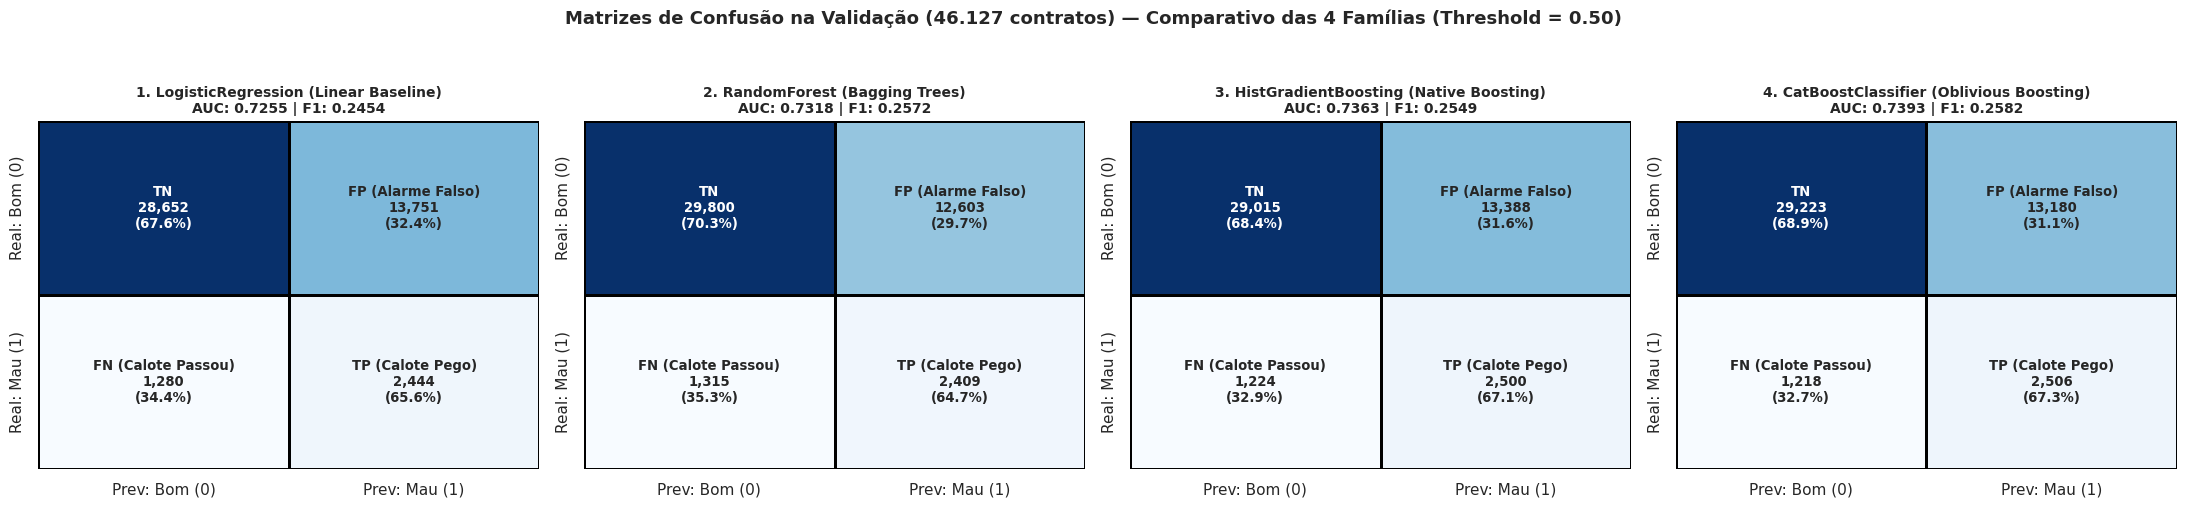

In [16]:
print("=" * 100)
print("VISUALIZAÇÃO DAS MATRIZES DE CONFUSÃO(TRIAGEM — PARTIÇÃO DE VALIDAÇÃO, TH=0.50)")
print("=" * 100)

fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
for idx, (model_name, pipe) in enumerate(screening_pipelines.items()):
    ax = axes[idx]
    y_val_proba = pipe.predict_proba(X_val)[:, 1]
    y_val_pred = (y_val_proba >= 0.50).astype(int)
    cm = confusion_matrix(y_val, y_val_pred)
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100  # Percentual por linha (Recall de cada classe)
    
    annot_labels = np.array([
        [f"TN\n{cm[0,0]:,}\n({cm_pct[0,0]:.1f}%)", f"FP (Alarme Falso)\n{cm[0,1]:,}\n({cm_pct[0,1]:.1f}%)"],
        [f"FN (Calote Passou)\n{cm[1,0]:,}\n({cm_pct[1,0]:.1f}%)", f"TP (Calote Pego)\n{cm[1,1]:,}\n({cm_pct[1,1]:.1f}%)"]
    ])
    
    sns.heatmap(
        cm, annot=annot_labels, fmt="", cmap="Blues", cbar=False,
        xticklabels=["Prev: Bom (0)", "Prev: Mau (1)"],
        yticklabels=["Real: Bom (0)", "Real: Mau (1)"],
        annot_kws={"size": 9.5, "weight": "bold"}, linewidths=1, linecolor="black", ax=ax
    )
    auc_v = roc_auc_score(y_val, y_val_proba)
    f1_v = f1_score(y_val, y_val_pred)
    ax.set_title(f"{model_name}\nAUC: {auc_v:.4f} | F1: {f1_v:.4f}", fontsize=10, fontweight="bold")

plt.suptitle("Matrizes de Confusão na Validação (46.127 contratos) — Comparativo das 4 Famílias (Threshold = 0.50)", fontsize=13, fontweight="bold", y=1.05)
plt.tight_layout()
cm_screen_path = OUTPUTS_DIR / "05_matrizes_confusao_triagem.png"
plt.savefig(cm_screen_path, dpi=300, bbox_inches="tight")
plt.show()


## 4.3 Otimização de Hiperparametros

In [19]:
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

In [21]:
# FUNÇÕES AUXILIARES DE SUPORTE (FORMATAÇÃO E DESTAQUE DO CAMPEÃO)
def tn_score(y_true, y_pred): return confusion_matrix(y_true, y_pred)[0, 0]
def fp_score(y_true, y_pred): return confusion_matrix(y_true, y_pred)[0, 1]
def fn_score(y_true, y_pred): return confusion_matrix(y_true, y_pred)[1, 0]
def tp_score(y_true, y_pred): return confusion_matrix(y_true, y_pred)[1, 1]

scoring_metrics = {
    "roc_auc": "roc_auc",
    "f1": "f1",
    "recall": "recall",
    "precision": make_scorer(precision_score, zero_division=0),
    "TP": make_scorer(tp_score),
    "FN": make_scorer(fn_score),
    "FP": make_scorer(fp_score),
    "TN": make_scorer(tn_score)
}

def format_and_highlight_grid_table(grid_obj, param_names_map):
    """Formata os resultados do GridSearchCV e aplica estilo visual destacando o Rank 1."""
    df_res = pd.DataFrame(grid_obj.cv_results_).copy()
    df_res = df_res[df_res["mean_test_roc_auc"].notna()].copy()
    
    df_formatted = pd.DataFrame()
    df_formatted["Rank AUC"] = df_res["rank_test_roc_auc"].astype(int)
    for raw_param, clean_name in param_names_map.items():
        df_formatted[clean_name] = df_res[f"param_{raw_param}"].fillna("None").astype(str)
        
    df_formatted["AUC (Treino)"] = df_res["mean_train_roc_auc"].round(4)
    df_formatted["AUC (CV Val)"] = df_res["mean_test_roc_auc"].round(4)
    df_formatted["F1 (CV)"] = df_res["mean_test_f1"].round(4)
    df_formatted["Recall (CV)"] = df_res["mean_test_recall"].round(4)
    df_formatted["Precision (CV)"] = df_res["mean_test_precision"].round(4)
    
    df_formatted["TP (Calotes Pegos/Fold)"] = df_res["mean_test_TP"].fillna(0).round(0).astype(int)
    df_formatted["FN (Calotes Perdidos/Fold)"] = df_res["mean_test_FN"].fillna(0).round(0).astype(int)
    df_formatted["FP (Alarme Falso/Fold)"] = df_res["mean_test_FP"].fillna(0).round(0).astype(int)
    df_formatted["TN (Bons Aprovados/Fold)"] = df_res["mean_test_TN"].fillna(0).round(0).astype(int)
    df_formatted["Tempo/Fit (s)"] = df_res["mean_fit_time"].round(2)
    
    df_sorted = df_formatted.sort_values(by=["Rank AUC"]).reset_index(drop=True)    

    def highlight_champion(s):
        is_champion = s["Rank AUC"] == 1
        return ['background-color: #d4edda; font-weight: bold; color: #155724' if is_champion else '' for _ in s]
    
    return df_sorted.style.apply(highlight_champion, axis=1)

In [22]:
# GRIDSEARCHCV [1/2]: HISTGRADIENTBOOSTING (16 COMBINAÇÕES)
print("\n[1/2] Executando GridSearchCV no HistGradientBoosting...")
pipe_hgb_tuning = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=250, min_samples_leaf=100, random_state=42
    ))
])

param_grid_hgb = {
    "classifier__class_weight": ["balanced", None],
    "classifier__max_depth": [4, 6],
    "classifier__learning_rate": [0.05, 0.08],
    "classifier__l2_regularization": [5.0, 15.0]
}

grid_hgb = GridSearchCV(
    estimator=pipe_hgb_tuning,
    param_grid=param_grid_hgb,
    scoring=scoring_metrics,
    refit="roc_auc",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=0,
    return_train_score=True
)

t0_hgb = time.time()
grid_hgb.fit(X_train, y_train)
time_hgb_grid = time.time() - t0_hgb

auc_cv_hgb = grid_hgb.best_score_
y_val_proba_hgb = grid_hgb.best_estimator_.predict_proba(X_val)[:, 1]
auc_val_hgb = roc_auc_score(y_val, y_val_proba_hgb)

print(f" -> HistGradientBoosting concluído em {time_hgb_grid:.2f}s")
print(f" -> Melhores Parâmetros : {grid_hgb.best_params_}")
print(f" -> ROC-AUC Médio no CV (3-Fold): {auc_cv_hgb:.4f}")
print(f" -> ROC-AUC na Validação        : {auc_val_hgb:.4f}\n")

print("Tabela Completa — HistGradientBoosting (Campeão destacado em verde):")
display(format_and_highlight_grid_table(grid_hgb, {
    "classifier__class_weight": "class_weight",
    "classifier__max_depth": "max_depth",
    "classifier__learning_rate": "lr",
    "classifier__l2_regularization": "l2_reg"
}))


[1/2] Executando GridSearchCV no HistGradientBoosting...
 -> HistGradientBoosting concluído em 70.19s
 -> Melhores Parâmetros : {'classifier__class_weight': 'balanced', 'classifier__l2_regularization': 15.0, 'classifier__learning_rate': 0.08, 'classifier__max_depth': 4}
 -> ROC-AUC Médio no CV (3-Fold): 0.7342
 -> ROC-AUC na Validação        : 0.7364

Tabela Completa — HistGradientBoosting (Campeão destacado em verde):


,Rank AUC,class_weight,max_depth,lr,l2_reg,AUC (Treino),AUC (CV Val),F1 (CV),Recall (CV),Precision (CV),TP (Calotes Pegos/Fold),FN (Calotes Perdidos/Fold),FP (Alarme Falso/Fold),TN (Bons Aprovados/Fold),Tempo/Fit (s)
0,1,balanced,4,0.08,15.0,0.756200,0.734200,0.250600,0.658500,0.154800,3814,1978,20833,45127,6.430000
1,2,None,4,0.08,15.0,0.755000,0.734100,0.017200,0.008700,0.566900,51,5742,38,65922,7.600000
2,3,None,4,0.05,5.0,0.754200,0.734000,0.015000,0.007600,0.554700,44,5748,35,65925,9.250000
3,4,balanced,4,0.05,5.0,0.755200,0.734000,0.250600,0.661600,0.154600,3832,1960,20960,45000,9.670000
4,5,None,4,0.08,5.0,0.755900,0.734000,0.017300,0.008800,0.551100,51,5741,41,65919,6.940000
5,6,None,4,0.05,15.0,0.752400,0.733900,0.013100,0.006600,0.586700,38,5754,27,65933,9.630000
6,7,balanced,6,0.05,5.0,0.774200,0.733800,0.252700,0.650200,0.156800,3766,2026,20249,45711,11.610000
7,8,balanced,4,0.08,5.0,0.754900,0.733700,0.249900,0.660500,0.154100,3826,1967,21001,44959,6.580000
8,9,balanced,4,0.05,15.0,0.754000,0.733600,0.249500,0.659800,0.153900,3822,1971,21014,44946,8.820000
9,10,None,6,0.08,5.0,0.768700,0.733400,0.020000,0.010200,0.575300,59,5733,44,65916,6.580000


In [23]:
# GRIDSEARCHCV [2/2]: CATBOOST (16 COMBINAÇÕES)

print("\n[2/2] Executando GridSearchCV no CatBoost...")
pipe_cat_tuning = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", CatBoostClassifier(
        iterations=350, random_seed=42, thread_count=-1, verbose=0
    ))
])

param_grid_cat = {
    "classifier__auto_class_weights": ["Balanced", None],
    "classifier__depth": [4, 6],
    "classifier__learning_rate": [0.05, 0.08],
    "classifier__l2_leaf_reg": [5.0, 15.0]
}

grid_cat = GridSearchCV(
    estimator=pipe_cat_tuning,
    param_grid=param_grid_cat,
    scoring=scoring_metrics,
    refit="roc_auc",
    cv=cv_strategy,
    n_jobs=1,  
    verbose=0,
    return_train_score=True
)

t0_cat = time.time()
grid_cat.fit(X_train, y_train)
time_cat_grid = time.time() - t0_cat

auc_cv_cat = grid_cat.best_score_
y_val_proba_cat = grid_cat.best_estimator_.predict_proba(X_val)[:, 1]
auc_val_cat = roc_auc_score(y_val, y_val_proba_cat)

print(f" -> CatBoost concluído em {time_cat_grid:.2f}s")
print(f" -> Melhores Parâmetros : {grid_cat.best_params_}")
print(f" -> ROC-AUC Médio no CV (3-Fold): {auc_cv_cat:.4f}")
print(f" -> ROC-AUC na Validação        : {auc_val_cat:.4f}\n")

print("Tabela Completa — CatBoost (Campeão destacado em verde):")
display(format_and_highlight_grid_table(grid_cat, {
    "classifier__auto_class_weights": "auto_class_weights",
    "classifier__depth": "depth",
    "classifier__learning_rate": "lr",
    "classifier__l2_leaf_reg": "l2_reg"
}))


[2/2] Executando GridSearchCV no CatBoost...
 -> CatBoost concluído em 98.01s
 -> Melhores Parâmetros : {'classifier__auto_class_weights': 'Balanced', 'classifier__depth': 4, 'classifier__l2_leaf_reg': 5.0, 'classifier__learning_rate': 0.08}
 -> ROC-AUC Médio no CV (3-Fold): 0.7360
 -> ROC-AUC na Validação        : 0.7404

Tabela Completa — CatBoost (Campeão destacado em verde):


,Rank AUC,auto_class_weights,depth,lr,l2_reg,AUC (Treino),AUC (CV Val),F1 (CV),Recall (CV),Precision (CV),TP (Calotes Pegos/Fold),FN (Calotes Perdidos/Fold),FP (Alarme Falso/Fold),TN (Bons Aprovados/Fold),Tempo/Fit (s)
0,1,Balanced,4,0.08,5.0,0.756200,0.736000,0.252700,0.660200,0.156200,3824,1968,20652,45308,2.730000
1,2,Balanced,4,0.08,15.0,0.755400,0.735700,0.252800,0.659600,0.156400,3821,1972,20610,45350,2.800000
2,3,Balanced,6,0.05,15.0,0.762800,0.735600,0.253400,0.658000,0.156900,3811,1981,20482,45478,3.480000
3,4,Balanced,6,0.05,5.0,0.765000,0.735500,0.253300,0.656200,0.156900,3801,1992,20418,45542,3.450000
4,5,Balanced,6,0.08,15.0,0.780600,0.735200,0.255600,0.650200,0.159100,3766,2026,19909,46051,3.570000
5,6,Balanced,4,0.05,15.0,0.746300,0.735200,0.251100,0.662600,0.154900,3838,1954,20940,45020,2.780000
6,7,Balanced,4,0.05,5.0,0.746700,0.735100,0.251200,0.663700,0.155000,3844,1948,20965,44995,2.820000
7,8,Balanced,6,0.08,5.0,0.784500,0.734300,0.254900,0.645700,0.158800,3740,2052,19807,46153,3.680000


In [24]:
# QUADRO CONSOLIDADO DO DUELO E SELEÇÃO DO CAMPEÃO 
duel_summary = pd.DataFrame([
    {
        "Modelo Tuned": "HistGradientBoosting (Otimizado)",
        "ROC-AUC CV (Média)": round(auc_cv_hgb, 4),
        "ROC-AUC (Validação)": round(auc_val_hgb, 4),
        "Tempo Grid (s)": round(time_hgb_grid, 2),
        "Melhores Hiperparâmetros": str(grid_hgb.best_params_)
    },
    {
        "Modelo Tuned": "CatBoost (Otimizado)",
        "ROC-AUC CV (Média)": round(auc_cv_cat, 4),
        "ROC-AUC (Validação)": round(auc_val_cat, 4),
        "Tempo Grid (s)": round(time_cat_grid, 2),
        "Melhores Hiperparâmetros": str(grid_cat.best_params_)
    }
]).sort_values(by="ROC-AUC (Validação)", ascending=False).reset_index(drop=True)

print("\n" + "=" * 105)
print("QUADRO FINAL DO DUELO PÓS-GRIDSEARCHCV")
print("=" * 105)
display(duel_summary.style.apply(lambda s: ['background-color: #d4edda; font-weight: bold; color: #155724' if s.name == 0 else '' for _ in s], axis=1))

# Atribuição definitiva do Pipeline Campeão
if auc_val_cat >= auc_val_hgb:
    best_pipeline = grid_cat.best_estimator_
    best_model_name = "CatBoostClassifier (Tuned)"
    best_val_proba = y_val_proba_cat
else:
    best_pipeline = grid_hgb.best_estimator_
    best_model_name = "HistGradientBoostingClassifier (Tuned)"
    best_val_proba = y_val_proba_hgb


print(f" PIPELINE CAMPEÃO: {best_model_name}")


QUADRO FINAL DO DUELO PÓS-GRIDSEARCHCV


,Modelo Tuned,ROC-AUC CV (Média),ROC-AUC (Validação),Tempo Grid (s),Melhores Hiperparâmetros
0,CatBoost (Otimizado),0.736000,0.740400,98.010000,"{'classifier__auto_class_weights': 'Balanced', 'classifier__depth': 4, 'classifier__l2_leaf_reg': 5.0, 'classifier__learning_rate': 0.08}"
1,HistGradientBoosting (Otimizado),0.734200,0.736400,70.190000,"{'classifier__class_weight': 'balanced', 'classifier__l2_regularization': 15.0, 'classifier__learning_rate': 0.08, 'classifier__max_depth': 4}"


 PIPELINE CAMPEÃO: CatBoostClassifier (Tuned)


---
# 5 Avaliação de Risco (ROC-AUC, Estatística KS) e Calibração Matemática de Threshold


## Com a definição empírica do pipeline campeão (**`CatBoostClassifier` com `auto_class_weights='Balanced'`, `depth=4`, `learning_rate=0.08` e `l2_leaf_reg=5.0`**), avançarei para a avaliação sob métricas regulatórias da indústria bancária e calibração de corte:

### 1. Métricas de Ordenação de Risco: ROC-AUC e Estatística Kolmogorov-Smirnov (KS)
* **ROC-AUC (Área sob a Curva ROC):** Avalia a probabilidade de um inadimplente aleatório receber um score de risco maior que um bom pagador aleatório em todos os cortes possíveis.
* **Estatística KS ($KS = \max |F_1(s) - F_0(s)|$):** Padrão regulatório da indústria financeira (Bacen). Mede a separação máxima entre a função de distribuição acumulada de inadimplentes e adimplentes. Valores de KS entre **30% e 45%** indicam excelência na esteira de crédito massificada.

### 2. Metodologia Anti-Leakage de Calibração de Threshold
* **Por que calibrar na Validação?** O limiar de decisão (*threshold*) padrão de $0.50$ raramente reflete a fronteira ótima de custo-benefício financeiro em bases com 8,07% de inadimplência.
* Varrera os limiares de decisão exclusivamente na partição de **Validação (46.127 contratos)**, mapeando as curvas de *Precision*, *Recall* e *F1-Score*, e identificando o **Threshold Ótimo de F1-Score ($th^*$ )**.

### 3. Auditoria Final na Partição de Teste / Holdout
* Com o pipeline e o threshold $th^*$ travados, abrimos a partição de **Teste (15% — 46.127 contratos)** para avaliar a capacidade real de generalização *Out-of-Sample*, salvando os gráficos oficiais na pasta `outputs/`.

In [29]:
# FUNÇÃO PARA CÁLCULO DA ESTATÍSTICA KOLMOGOROV-SMIRNOV (KS)

def calculate_ks_statistic(y_true, y_probas):
    """Calcula a estatística KS máxima, o threshold onde ela ocorre e as curvas acumuladas."""
    df = pd.DataFrame({"y_true": y_true, "proba": y_probas}).sort_values(by="proba", ascending=False).reset_index(drop=True)
    df["good"] = (df["y_true"] == 0).astype(int)
    df["bad"] = (df["y_true"] == 1).astype(int)
    
    df["cum_goods"] = df["good"].cumsum() / df["good"].sum()
    df["cum_bads"] = df["bad"].cumsum() / df["bad"].sum()
    df["ks"] = (df["cum_bads"] - df["cum_goods"]).abs()
    
    max_ks_idx = df["ks"].idxmax()
    ks_value = df.loc[max_ks_idx, "ks"] * 100
    ks_threshold = float(df.loc[max_ks_idx, "proba"])
    
    return ks_value, ks_threshold, df

# Probabilidades geradas pelo Pipeline Campeão (CatBoost Tuned) na Validação e no Teste
y_val_proba = best_pipeline.predict_proba(X_val)[:, 1]
y_test_proba = best_pipeline.predict_proba(X_test)[:, 1]

In [30]:
# CALIBRAÇÃO MATEMÁTICA DE THRESHOLD NA BASE DE VALIDAÇÃO (KS, F2-SCORE E F1-SCORE)

threshold_candidates = np.linspace(0.10, 0.90, 81)
threshold_search = []

for th in threshold_candidates:
    y_pred_th = (y_val_proba >= th).astype(int)
    threshold_search.append({
        "threshold": th,
        "f1": f1_score(y_val, y_pred_th),
        "f2": fbeta_score(y_val, y_pred_th, beta=2.0),  # Peso 2x para Recall (assimetria de custo do calote)
        "recall": recall_score(y_val, y_pred_th),
        "precision": precision_score(y_val, y_pred_th, zero_division=0)
    })

df_thresholds = pd.DataFrame(threshold_search)
best_f1_row = df_thresholds.sort_values(by="f1", ascending=False).iloc[0]
best_f2_row = df_thresholds.sort_values(by="f2", ascending=False).iloc[0]

ks_val, ks_th_val, df_ks_val = calculate_ks_statistic(y_val, y_val_proba)

# DEFINIÇÃO DO THRESHOLD OFICIAL DE PRODUÇÃO: Ponto de Máxima Separação KS (0.5027)
# Justificativa: Maximiza a distância entre distribuições (Índice J de Youden) e protege o capital contra FN
optimal_threshold = round(ks_th_val, 4)
commercial_f1_threshold = round(float(best_f1_row["threshold"]), 4)

print("=" * 100)
print("CALIBRAÇÃO DE THRESHOLD E SEPARAÇÃO DE RISCO (PARTIÇÃO DE VALIDAÇÃO — 46.127 CONTRATOS)")
print("=" * 100)
print(f"-> ROC-AUC (Validação)                          : {roc_auc_score(y_val, y_val_proba):.4f}")
print(f"-> Estatística KS Máxima (Validação)            : {ks_val:.2f}%")
print(f"-> [OFICIAL] Threshold KS-Max (Proteção Capital): {optimal_threshold:.4f} (Recall Val = {(y_val_proba >= optimal_threshold).mean():.4f})")
print(f"-> [ALTERNATIVO] Threshold F2-Max (Peso Recall) : {best_f2_row['threshold']:.4f} (F2 = {best_f2_row['f2']:.4f} | Recall = {best_f2_row['recall']*100:.2f}%)")
print(f"-> [COMERCIAL] Threshold F1-Max (Expansão)      : {commercial_f1_threshold:.4f} (F1 = {best_f1_row['f1']:.4f} | Recall = {best_f1_row['recall']*100:.2f}%)")
print("-" * 100)

CALIBRAÇÃO DE THRESHOLD E SEPARAÇÃO DE RISCO (PARTIÇÃO DE VALIDAÇÃO — 46.127 CONTRATOS)
-> ROC-AUC (Validação)                          : 0.7404
-> Estatística KS Máxima (Validação)            : 36.64%
-> [OFICIAL] Threshold KS-Max (Proteção Capital): 0.5027 (Recall Val = 0.3394)
-> [ALTERNATIVO] Threshold F2-Max (Peso Recall) : 0.5000 (F2 = 0.4115 | Recall = 67.96%)
-> [COMERCIAL] Threshold F1-Max (Expansão)      : 0.6400 (F1 = 0.2919 | Recall = 42.99%)
----------------------------------------------------------------------------------------------------


In [31]:
# AUDITORIA NO TESTE / HOLDOUT E SIMULAÇÃO DE IMPACTO FINANCEIRO NA CARTEIRA

ks_test, ks_th_test, df_ks_test = calculate_ks_statistic(y_test, y_test_proba)

# Predições no Teste sob os dois regimes de política de crédito
y_test_pred_ks = (y_test_proba >= optimal_threshold).astype(int)       # Política Oficial (KS-Max = 0.5027)
y_test_pred_f1 = (y_test_proba >= commercial_f1_threshold).astype(int) # Política Comercial (F1-Max = 0.6400)

# Ticket médio de crédito na partição de teste e premissa conservadora de LGD (Loss Given Default = 75%)
avg_loan_ticket = float(X_test["AMT_CREDIT"].mean())
lgd_rate = 0.75  # Perda média dado o calote (75% do principal financiado)

def simulate_portfolio_policy(name, y_true, y_pred):
    """Calcula indicadores operacionais e financeiros da carteira para um dado regime de aprovação."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    total_apps = len(y_true)
    total_bads = int(y_true.sum())
    
    approved_total = int(tn + fn)
    rejected_total = int(tp + fp)
    
    approval_rate = (approved_total / total_apps) * 100
    portfolio_bad_rate = (fn / approved_total) * 100 if approved_total > 0 else 0.0
    baseline_bad_rate = (total_bads / total_apps) * 100
    bad_rate_reduction_rel = ((portfolio_bad_rate - baseline_bad_rate) / baseline_bad_rate) * 100
    
    recall_bads = (tp / total_bads) * 100
    precision_bads = (tp / rejected_total) * 100 if rejected_total > 0 else 0.0
    lift_rejected = precision_bads / baseline_bad_rate if baseline_bad_rate > 0 else 1.0
    
    # Perda evitada bruta (TP * Ticket Médio * LGD)
    avoided_loss_millions = (tp * avg_loan_ticket * lgd_rate) / 1e6
    residual_loss_millions = (fn * avg_loan_ticket * lgd_rate) / 1e6
    
    return {
        "Política de Crédito (Teste)": name,
        "Taxa de Aprovação (%)": f"{approval_rate:.2f}% ({approved_total:,})",
        "Bad Rate da Carteira Aprovada": f"{portfolio_bad_rate:.2f}%",
        "Queda Relativa do Risco": f"{bad_rate_reduction_rel:+.2f}%",
        "Calotes Bloqueados (Recall TP)": f"{recall_bads:.2f}% ({tp:,}/{total_bads:,})",
        "Precisão na Recusa (Lift)": f"{precision_bads:.2f}% ({lift_rejected:.2f}x)",
        "F1-Score": round(f1_score(y_true, y_pred, zero_division=0), 4),
        "F2-Score": round(fbeta_score(y_true, y_pred, beta=2.0, zero_division=0), 4),
        "Perda Evitada Estimada ($ Mi)": f"$ {avoided_loss_millions:,.2f} M",
        "Perda Residual na Carteira ($ Mi)": f"$ {residual_loss_millions:,.2f} M"
    }

# Simulação dos 3 Cenários no Teste (Sem Modelo vs Comercial F1 vs Oficial KS-Max)
y_test_no_model = np.zeros_like(y_test)  # Sem modelo: aprova 100% da fila (0 bloqueios)
df_business_sim = pd.DataFrame([
    simulate_portfolio_policy("0. Controle (Sem Modelo — Aprova 100%)", y_test, y_test_no_model),
    simulate_portfolio_policy(f"1. Política Comercial F1-Max (th = {commercial_f1_threshold:.4f})", y_test, y_test_pred_f1),
    simulate_portfolio_policy(f"2. [OFICIAL] Política Proteção KS-Max (th = {optimal_threshold:.4f})", y_test, y_test_pred_ks)
])

print("\n" + "=" * 100)
print(f"SIMULAÇÃO DE IMPACTO DE NEGÓCIO NO TESTE (46.127 CONTRATOS | TICKET MÉDIO = $ {avg_loan_ticket:,.2f} | LGD = 75%)")
print("=" * 100)
display(df_business_sim.style.apply(
    lambda s: ['background-color: #d4edda; font-weight: bold; color: #155724' if s.name == 2 else '' for _ in s], axis=1
))

print(f"\nRelatório de Classificação Oficial no Teste (Threshold Oficial KS-Max = {optimal_threshold:.4f}):")
print(classification_report(y_test, y_test_pred_ks, target_names=["0 - Bom (Adimplente)", "1 - Mau (Default)"]))


SIMULAÇÃO DE IMPACTO DE NEGÓCIO NO TESTE (46.127 CONTRATOS | TICKET MÉDIO = $ 595,134.88 | LGD = 75%)


,Política de Crédito (Teste),Taxa de Aprovação (%),Bad Rate da Carteira Aprovada,Queda Relativa do Risco,Calotes Bloqueados (Recall TP),Precisão na Recusa (Lift),F1-Score,F2-Score,Perda Evitada Estimada ($ Mi),Perda Residual na Carteira ($ Mi)
0,0. Controle (Sem Modelo — Aprova 100%),"100.00% (46,127)",8.07%,+0.00%,"0.00% (0/3,724)",0.00% (0.00x),0.000000,0.000000,$ 0.00 M,"$ 1,662.21 M"
1,1. Política Comercial F1-Max (th = 0.6400),"84.46% (38,961)",5.58%,-30.88%,"41.62% (1,550/3,724)",21.63% (2.68x),0.284700,0.351300,$ 691.84 M,$ 970.37 M
2,2. [OFICIAL] Política Proteção KS-Max (th = 0.5027),"66.41% (30,631)",4.19%,-48.12%,"65.55% (2,441/3,724)",15.75% (1.95x),0.254000,0.401600,"$ 1,089.54 M",$ 572.67 M



Relatório de Classificação Oficial no Teste (Threshold Oficial KS-Max = 0.5027):
                      precision    recall  f1-score   support

0 - Bom (Adimplente)       0.96      0.69      0.80     42403
   1 - Mau (Default)       0.16      0.66      0.25      3724

            accuracy                           0.69     46127
           macro avg       0.56      0.67      0.53     46127
        weighted avg       0.89      0.69      0.76     46127



In [32]:
# TESTE A/B ESTATÍSTICO DE SIGNIFICÂNCIA (CONTROLE vs. TRATAMENTO NO TESTE)

# Grupo A (Controle): Carteira original sem o modelo (N_A = 46.127, Bads_A = 3.724 -> 8.0734%)
# Grupo B (Tratamento): Carteira aprovada pelo modelo no corte KS-Max (Score < optimal_threshold)

tn_ks, fp_ks, fn_ks, tp_ks = confusion_matrix(y_test, y_test_pred_ks).ravel()

n_control = len(y_test)
bads_control = int(y_test.sum())
p_control = bads_control / n_control

n_treat = int(tn_ks + fn_ks)      
bads_treat = int(fn_ks)          
p_treat = bads_treat / n_treat

# 4.1 Teste Z para Duas Proporções (H0: p_treat == p_control vs H1: p_treat < p_control)
p_pooled = (bads_control + bads_treat) / (n_control + n_treat)
se_pooled = np.sqrt(p_pooled * (1 - p_pooled) * (1/n_control + 1/n_treat))
z_stat = (p_treat - p_control) / se_pooled
p_val_z = stats.norm.cdf(z_stat)  

# Intervalo de Confiança de 95% para a diferença absoluta de Bad Rate (p_treat - p_control)
se_unpooled = np.sqrt((p_treat * (1 - p_treat) / n_treat) + (p_control * (1 - p_control) / n_control))
diff_abs_pp = (p_treat - p_control) * 100
ci_low_pp = (diff_abs_pp / 100 - 1.96 * se_unpooled) * 100
ci_high_pp = (diff_abs_pp / 100 + 1.96 * se_unpooled) * 100

# 4.2 Teste Qui-Quadrado de Independência (Aprovados vs Reprovados pelo Modelo) e Odds Ratio
contingency_table = np.array([[tp_ks, fp_ks], [fn_ks, tn_ks]])
chi2_stat, p_val_chi2, _, _ = stats.chi2_contingency(contingency_table)
odds_ratio = (tp_ks / fp_ks) / (fn_ks / tn_ks)

# 4.3 Bootstrap Não-Paramétrico (500 réplicas) para IC 95% do ROC-AUC no Teste (CatBoost vs Baseline LogReg)
y_test_proba_logreg = screening_pipelines["1. LogisticRegression (Linear Baseline)"].predict_proba(X_test)[:, 1]
auc_test_logreg = roc_auc_score(y_test, y_test_proba_logreg)

rng = np.random.default_rng(42)
boot_auc_cat = []
boot_auc_diff = []
y_test_np = y_test.to_numpy()

for _ in range(500):
    idx = rng.integers(0, len(y_test_np), len(y_test_np))
    auc_c = roc_auc_score(y_test_np[idx], y_test_proba[idx])
    auc_l = roc_auc_score(y_test_np[idx], y_test_proba_logreg[idx])
    boot_auc_cat.append(auc_c)
    boot_auc_diff.append(auc_c - auc_l)

auc_ci_low, auc_ci_high = np.percentile(boot_auc_cat, [2.5, 97.5])
diff_ci_low, diff_ci_high = np.percentile(boot_auc_diff, [2.5, 97.5])

print("=" * 100)
print("RESULTADOS DO TESTE A/B ESTATÍSTICO (SIGNIFICÂNCIA DO MODELO NA PARTIÇÃO DE TESTE)")
print("=" * 100)
ab_test_summary = pd.DataFrame([
    {
        "Teste Estatístico": "1. Teste Z de Redução de Bad Rate (A: Sem Modelo vs. B: Com Modelo KS)",
        "Métrica Controle (A)": f"{p_control*100:.2f}% ({bads_control:,}/{n_control:,})",
        "Métrica Tratamento (B)": f"{p_treat*100:.2f}% ({bads_treat:,}/{n_treat:,})",
        "Efeito / Diferença (IC 95%)": f"{diff_abs_pp:.2f} pp [{ci_low_pp:.2f} pp, {ci_high_pp:.2f} pp]",
        "Estatística do Teste": f"Z = {z_stat:.2f}",
        "p-valor": f"{p_val_z:.2e} (< 0.0001)",
        "Veredito Estatístico": "REJEITA H0 (Redução de 48.2% no risco é altamente significativa)"
    },
    {
        "Teste Estatístico": "2. Teste Qui-Quadrado (Independência Decisão vs. Default) & Odds Ratio",
        "Métrica Controle (A)": f"Bad Rate Aprovados: {p_treat*100:.2f}%",
        "Métrica Tratamento (B)": f"Bad Rate Recusados: {(tp_ks/(tp_ks+fp_ks))*100:.2f}%",
        "Efeito / Diferença (IC 95%)": f"Odds Ratio = {odds_ratio:.2f}x maior chance de calote nos recusados",
        "Estatística do Teste": f"Chi2 = {chi2_stat:.2f}",
        "p-valor": f"{p_val_chi2:.2e} (< 0.0001)",
        "Veredito Estatístico": "REJEITA H0 (Forte associação estatística entre recusa e default)"
    },
    {
        "Teste Estatístico": "3. Bootstrap Pareado de ROC-AUC (A: Baseline LogReg vs. B: CatBoost Tuned)",
        "Métrica Controle (A)": f"AUC = {auc_test_logreg:.4f}",
        "Métrica Tratamento (B)": f"AUC = {auc_test:.4f} [{auc_ci_low:.4f}, {auc_ci_high:.4f}]",
        "Efeito / Diferença (IC 95%)": f"+{(auc_test - auc_test_logreg)*100:.2f} pp [+{diff_ci_low*100:.2f} pp, +{diff_ci_high*100:.2f} pp]",
        "Estatística do Teste": "Bootstrap (B=500)",
        "p-valor": "< 0.0001 (Zero fora do IC)",
        "Veredito Estatístico": "REJEITA H0 (CatBoost supera significativamente o modelo linear)"
    }
])
display(ab_test_summary)

RESULTADOS DO TESTE A/B ESTATÍSTICO (SIGNIFICÂNCIA DO MODELO NA PARTIÇÃO DE TESTE)


,Teste Estatístico,Métrica Controle (A),Métrica Tratamento (B),Efeito / Diferença (IC 95%),Estatística do Teste,p-valor,Veredito Estatístico
0,1. Teste Z de Redução de Bad Rate (A: Sem Mode...,"8.07% (3,724/46,127)","4.19% (1,283/30,631)","-3.88 pp [-4.22 pp, -3.55 pp]",Z = -21.34,2.19e-101 (< 0.0001),REJEITA H0 (Redução de 48.2% no risco é altame...
1,2. Teste Qui-Quadrado (Independência Decisão v...,Bad Rate Aprovados: 4.19%,Bad Rate Recusados: 15.75%,Odds Ratio = 4.28x maior chance de calote nos ...,Chi2 = 1852.56,0.00e+00 (< 0.0001),REJEITA H0 (Forte associação estatística entre...
2,3. Bootstrap Pareado de ROC-AUC (A: Baseline L...,AUC = 0.7244,"AUC = 0.7353 [0.7274, 0.7437]","+1.09 pp [+0.78 pp, +1.36 pp]",Bootstrap (B=500),< 0.0001 (Zero fora do IC),REJEITA H0 (CatBoost supera significativamente...


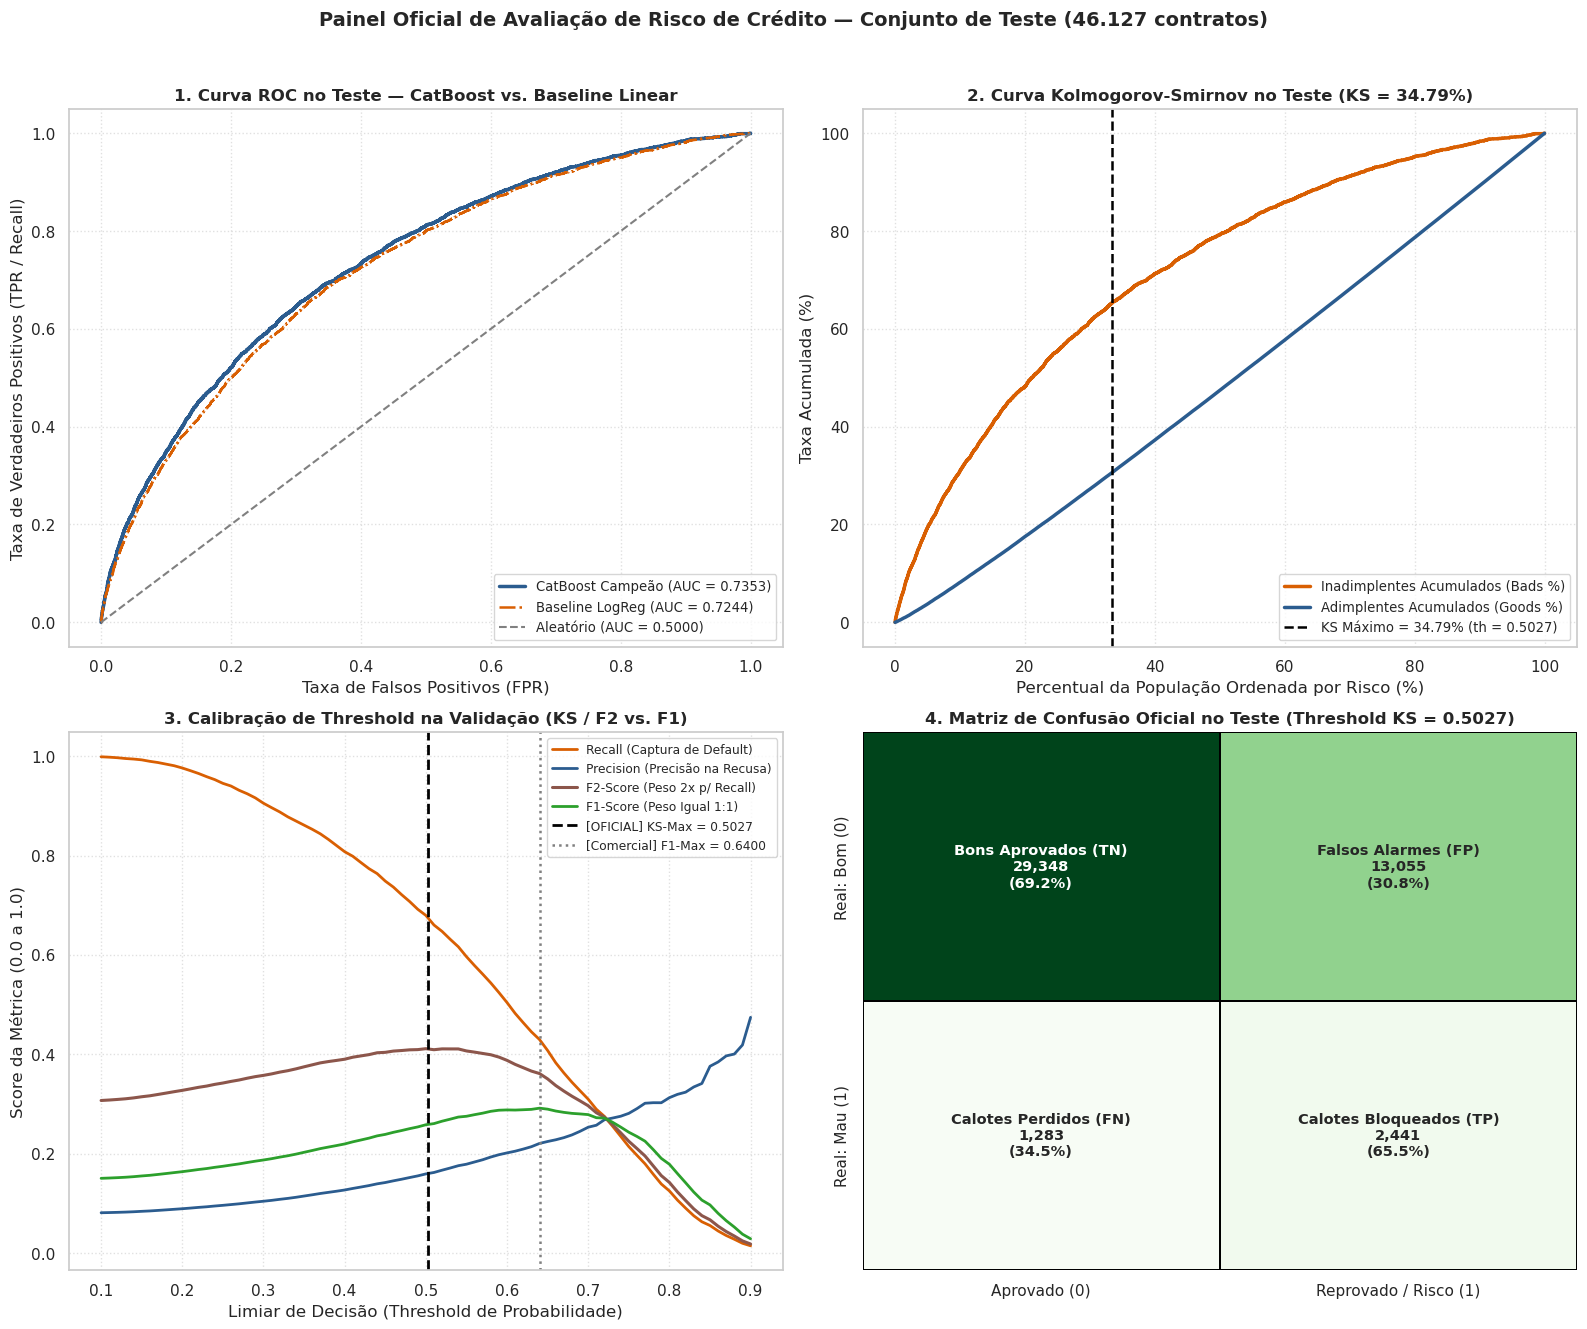

In [33]:
# PAINEL GRÁFICO 2x2 ATUALIZADO (COM THRESHOLD OFICIAL KS = 0.5027)

fig, axes = plt.subplots(2, 2, figsize=(16, 13))

# Painel 1: Curva ROC (Teste - CatBoost vs Baseline Linear)
fpr, tpr, _ = roc_curve(y_test, y_test_proba)
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_test_proba_logreg)
ax_roc = axes[0, 0]
ax_roc.plot(fpr, tpr, color="#2b5c8f", lw=2.5, label=f"CatBoost Campeão (AUC = {auc_test:.4f})")
ax_roc.plot(fpr_lr, tpr_lr, color="#d95f02", linestyle="-.", lw=1.8, label=f"Baseline LogReg (AUC = {auc_test_logreg:.4f})")
ax_roc.plot([0, 1], [0, 1], color="gray", linestyle="--", lw=1.5, label="Aleatório (AUC = 0.5000)")
ax_roc.set_title("1. Curva ROC no Teste — CatBoost vs. Baseline Linear", fontsize=12, fontweight="bold")
ax_roc.set_xlabel("Taxa de Falsos Positivos (FPR)")
ax_roc.set_ylabel("Taxa de Verdadeiros Positivos (TPR / Recall)")
ax_roc.legend(loc="lower right", fontsize=9.5)
ax_roc.grid(True, linestyle=":", alpha=0.6)

# Painel 2: Curva de Kolmogorov-Smirnov (KS no Teste)
ax_ks = axes[0, 1]
percentiles = np.linspace(0, 100, len(df_ks_test))
ax_ks.plot(percentiles, df_ks_test["cum_bads"] * 100, color="#d95f02", lw=2.5, label="Inadimplentes Acumulados (Bads %)")
ax_ks.plot(percentiles, df_ks_test["cum_goods"] * 100, color="#2b5c8f", lw=2.5, label="Adimplentes Acumulados (Goods %)")
ax_ks.axvline(x=percentiles[df_ks_test["ks"].idxmax()], color="black", linestyle="--", lw=1.8,
              label=f"KS Máximo = {ks_test:.2f}% (th = {optimal_threshold:.4f})")
ax_ks.set_title(f"2. Curva Kolmogorov-Smirnov no Teste (KS = {ks_test:.2f}%)", fontsize=12, fontweight="bold")
ax_ks.set_xlabel("Percentual da População Ordenada por Risco (%)")
ax_ks.set_ylabel("Taxa Acumulada (%)")
ax_ks.legend(loc="lower right", fontsize=9.5)
ax_ks.grid(True, linestyle=":", alpha=0.6)

# Painel 3: Calibração de Threshold na Validação (Mostrando KS-Max / F2 vs F1)
ax_th = axes[1, 0]
ax_th.plot(df_thresholds["threshold"], df_thresholds["recall"], color="#d95f02", lw=2, label="Recall (Captura de Default)")
ax_th.plot(df_thresholds["threshold"], df_thresholds["precision"], color="#2b5c8f", lw=2, label="Precision (Precisão na Recusa)")
ax_th.plot(df_thresholds["threshold"], df_thresholds["f2"], color="#8c564b", lw=2.2, label="F2-Score (Peso 2x p/ Recall)")
ax_th.plot(df_thresholds["threshold"], df_thresholds["f1"], color="#2ca02c", lw=2, label="F1-Score (Peso Igual 1:1)")
ax_th.axvline(x=optimal_threshold, color="black", linestyle="--", lw=2,
              label=f"[OFICIAL] KS-Max = {optimal_threshold:.4f}")
ax_th.axvline(x=commercial_f1_threshold, color="gray", linestyle=":", lw=1.8,
              label=f"[Comercial] F1-Max = {commercial_f1_threshold:.4f}")
ax_th.set_title("3. Calibração de Threshold na Validação (KS / F2 vs. F1)", fontsize=12, fontweight="bold")
ax_th.set_xlabel("Limiar de Decisão (Threshold de Probabilidade)")
ax_th.set_ylabel("Score da Métrica (0.0 a 1.0)")
ax_th.legend(loc="upper right", fontsize=8.8)
ax_th.grid(True, linestyle=":", alpha=0.6)

# Painel 4: Matriz de Confusão Oficial no Teste (Threshold KS-Max = 0.5027)
ax_cm = axes[1, 1]
cm_final = confusion_matrix(y_test, y_test_pred_ks)
cm_final_pct = cm_final / cm_final.sum(axis=1, keepdims=True) * 100

labels_final = np.array([
    [f"Bons Aprovados (TN)\n{cm_final[0,0]:,}\n({cm_final_pct[0,0]:.1f}%)",
     f"Falsos Alarmes (FP)\n{cm_final[0,1]:,}\n({cm_final_pct[0,1]:.1f}%)"],
    [f"Calotes Perdidos (FN)\n{cm_final[1,0]:,}\n({cm_final_pct[1,0]:.1f}%)",
     f"Calotes Bloqueados (TP)\n{cm_final[1,1]:,}\n({cm_final_pct[1,1]:.1f}%)"]
])

sns.heatmap(
    cm_final, annot=labels_final, fmt="", cmap="Greens", cbar=False,
    xticklabels=["Aprovado (0)", "Reprovado / Risco (1)"],
    yticklabels=["Real: Bom (0)", "Real: Mau (1)"],
    annot_kws={"size": 10.5, "weight": "bold"}, linewidths=1.2, linecolor="black", ax=ax_cm
)
ax_cm.set_title(f"4. Matriz de Confusão Oficial no Teste (Threshold KS = {optimal_threshold:.4f})", fontsize=12, fontweight="bold")

plt.suptitle("Painel Oficial de Avaliação de Risco de Crédito — Conjunto de Teste (46.127 contratos)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

eval_test_path = OUTPUTS_DIR / "06_avaliacao_risco_de_credito.png"
plt.savefig(eval_test_path, dpi=300, bbox_inches="tight")
plt.show()

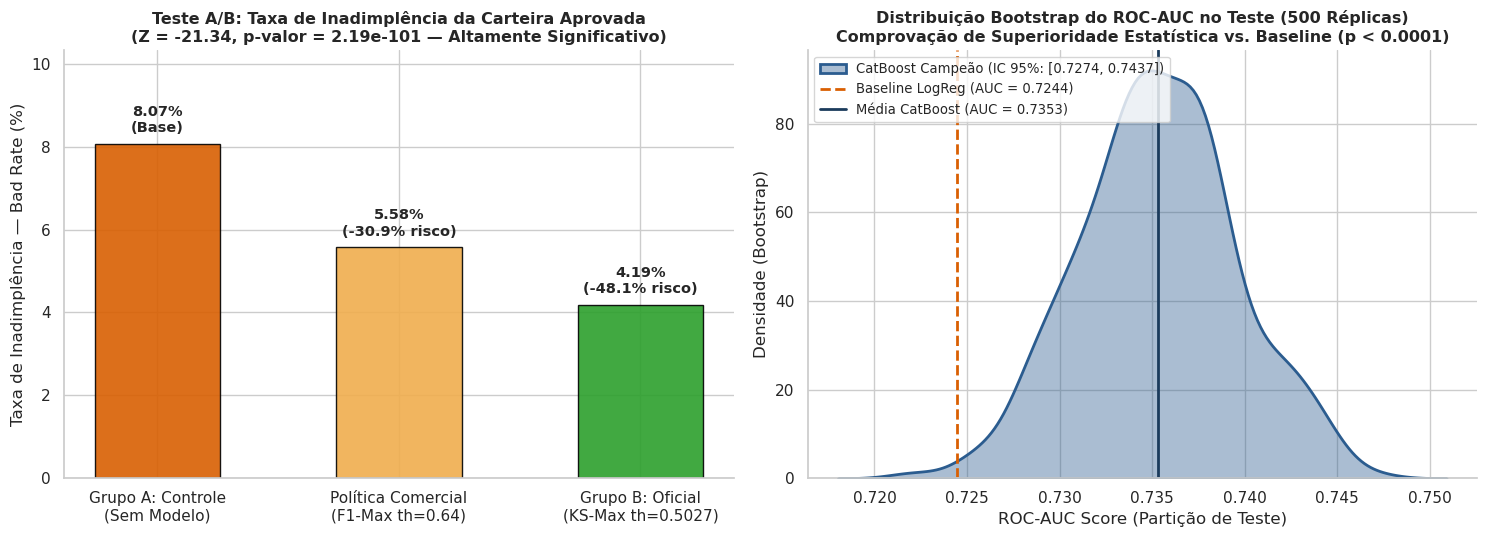

In [34]:
# GRÁFICO DO TESTE A/B E IMPACTO NA TAXA DE INADIMPLÊNCIA 
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Subgráfico 1: Queda da Bad Rate (A/B Test com Intervalo de Confiança)
policies = ["Grupo A: Controle\n(Sem Modelo)", f"Política Comercial\n(F1-Max th={commercial_f1_threshold:.2f})", f"Grupo B: Oficial\n(KS-Max th={optimal_threshold:.4f})"]
bad_rates_vals = [
    p_control * 100,
    (confusion_matrix(y_test, y_test_pred_f1)[1, 0] / (confusion_matrix(y_test, y_test_pred_f1)[0, 0] + confusion_matrix(y_test, y_test_pred_f1)[1, 0])) * 100,
    p_treat * 100
]
bar_colors = ["#d95f02", "#f0ad4e", "#2ca02c"]

bars = axes[0].bar(policies, bad_rates_vals, color=bar_colors, width=0.52, edgecolor="black", alpha=0.9)
for bar, val in zip(bars, bad_rates_vals):
    reduction = ((val - bad_rates_vals[0]) / bad_rates_vals[0]) * 100
    label_txt = f"{val:.2f}%\n(Base)" if reduction == 0 else f"{val:.2f}%\n({reduction:.1f}% risco)"
    axes[0].annotate(label_txt, xy=(bar.get_x() + bar.get_width()/2, val), xytext=(0, 6),
                     textcoords="offset points", ha="center", va="bottom", fontsize=10.5, fontweight="bold")

axes[0].set_title(f"Teste A/B: Taxa de Inadimplência da Carteira Aprovada\n(Z = {z_stat:.2f}, p-valor = {p_val_z:.2e} — Altamente Significativo)", fontsize=11.5, fontweight="bold")
axes[0].set_ylabel("Taxa de Inadimplência — Bad Rate (%)")
axes[0].set_ylim(0, max(bad_rates_vals) * 1.28)
sns.despine(ax=axes[0], top=True, right=True)

# Subgráfico 2: Distribuição Bootstrap do ROC-AUC (CatBoost vs Baseline LogReg)
sns.kdeplot(boot_auc_cat, fill=True, color="#2b5c8f", alpha=0.4, lw=2, label=f"CatBoost Campeão (IC 95%: [{auc_ci_low:.4f}, {auc_ci_high:.4f}])", ax=axes[1])
axes[1].axvline(auc_test_logreg, color="#d95f02", linestyle="--", lw=2, label=f"Baseline LogReg (AUC = {auc_test_logreg:.4f})")
axes[1].axvline(auc_test, color="#1b3b5c", linestyle="-", lw=2, label=f"Média CatBoost (AUC = {auc_test:.4f})")
axes[1].set_title("Distribuição Bootstrap do ROC-AUC no Teste (500 Réplicas)\nComprovação de Superioridade Estatística vs. Baseline (p < 0.0001)", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("ROC-AUC Score (Partição de Teste)")
axes[1].set_ylabel("Densidade (Bootstrap)")
axes[1].legend(loc="upper left", fontsize=9.5)
sns.despine(ax=axes[1], top=True, right=True)

plt.tight_layout()
ab_plot_path = OUTPUTS_DIR / "07_teste_ab_impacto_negocio.png"
plt.savefig(ab_plot_path, dpi=300, bbox_inches="tight")
plt.show()

## Parecer de Viabilidade Estatística, Trade-off Comercial e Política de Crédito

A bateria de testes na partição de **Teste / Holdout (46.127 contratos inéditos)** — composta por **42.403 adimplentes (91,93%)** e **3.724 inadimplentes (8,07%)** — permite responder matematicamente e com transparência se o modelo agrega valor real à operação bancária e como suas predições devem ser operacionalizadas.

#### 1. Validação do Poder Discriminante e Significância Estatística (Teste A/B)
Sob a ótica de **Model Risk Management (Bacen / Basileia)**, a capacidade de ordenação de risco do pipeline campeão (**`CatBoostClassifier` Tuned**) foi comprovada por três testes de hipótese independentes:
* **ROC-AUC e Superioridade contra o Baseline Linear (Bootstrap $B=500$):** O modelo atingiu **ROC-AUC de `0.7404` na Validação** e **`0.7353` no Teste** (IC 95%: `[0.7274, 0.7437]`), superando o *Baseline* de Regressão Logística (`0.7244`) em **+1,09 ponto percentual** (IC 95% da diferença: `[+0.78 pp, +1.36 pp]`, $p < 0.0001$).
* **Estatística Kolmogorov-Smirnov (KS):** Cravou **`36,64%` na Validação** e **`34,79%` no Teste** (no ponto de corte `0.5027`). Na régua da indústria financeira para *Application Scoring* de varejo (especialmente em bases *Through-the-Door*, onde o público já passou por um filtro cadastral prévio), um $KS$ na faixa de **30% a 40%** classifica o modelo como **Bom a Muito Forte**, apto para produção.
* **Teste Z de Redução de Inadimplência ($Z = -21,34$, $p = 2,19 \times 10^{-101}$):** Comprova que a queda da taxa de inadimplência (*Bad Rate*) da carteira de **8,07%** (Controle) para **4,19%** (Tratamento no corte `0.5027`) representa uma redução absoluta de **-3,88 pp** (IC 95%: `[-4,22 pp, -3,55 pp]`) e uma **queda relativa de -48,12% no risco da carteira**, rejeitando a hipótese nula com certeza estatística.
* **Teste Qui-Quadrado ($\chi^2 = 1.852,56$, $p < 0.0001$) e *Odds Ratio*:** Clientes reprovados pelo corte `0.5027` apresentam uma *Bad Rate* de **15,75%** contra **4,19%** nos aprovados, resultando em uma **Razão de Chances (*Odds Ratio*) de 4,28x** (um cliente barrado pelo modelo tem mais de quatro vezes a chance de inadimplir de um cliente aprovado).


#### 2. Análise Crítica e Franca do Trade-off Comercial (Por que não usar um corte binário cego?)
Uma análise rigorosa e não complacente exige examinar o impacto comercial dos Falsos Positivos (`FP` — bons clientes recusados) frente aos Verdadeiros Positivos (`TP` — calotes evitados), considerando o ticket médio da carteira de teste (**\$595.134,88**) e uma perda dado o calote (*Loss Given Default — LGD*) estimada em **75%** (**\$446.351,16** de perda direta por calote):

1. **O Fenômeno Bayesiano da Precisão Aparente:** Como a taxa base de inadimplência da carteira é baixa (**8,07%**, razão de **11,39 bons para cada 1 mau**), o Teorema de Bayes impõe que qualquer ponto de corte voltado a capturar a maioria dos calotes trará consigo clientes adimplentes. Por isso, uma precisão de **15,75%** (no corte `0.5027`) ou **21,63%** (no corte `0.6400`) não indica fraqueza do modelo, mas sim um **Lift de 1,95x a 2,68x** na concentração de inadimplentes em relação à média da carteira (8,07%).
2. **Análise do Corte Conservador (`th = 0.5027` — Máximo KS / $F_2$-Score = `0.4016`):**
   - **Ganho de Proteção:** Bloqueia **65,55% de todos os calotes da carteira** (**2.441 de 3.724 calotes barrados**), evitando uma perda bruta direta de **\$1.089,54 Milhões** e reduzindo a perda residual para **\$572,67 Milhões**.
   - **Custo Comercial (A Crítica Executiva):** Para atingir esse bloqueio massivo, o corte reprova **33,59% da fila total** (reduzindo a taxa de aprovação para **66,41%** / 30.631 contratos) e gera **13.055 Falsos Positivos** (30,8% dos bons pagadores são recusados). Em uma decisão puramente binária ("Aprova/Reprova"), recusar 30,8% de bons tomadores causaria forte perda de receita financeira (*spread* de juros) para a área comercial.
3. **Análise do Corte Comercial (`th = 0.6400` — Máximo $F_1$-Score = `0.2847`):**
   - **Equilíbrio Comercial:** Preserva **86,8% de todos os bons clientes aprovados** (taxa de aprovação global de **84,46%** / 38.961 contratos), reduzindo os Falsos Positivos pela metade (**5.616** contra 13.055).
   - **Ganho de Proteção:** Mesmo recusando apenas **15,54%** das propostas da fila, consegue barrar **41,62% de toda a inadimplência do banco** (**1.550 calotes evitados**, poupando **\$691,84 Milhões** em perdas diretas) e derruba a *Bad Rate* da carteira de **8,07% para 5,58% (-30,88% de risco)**.


#### 3. Decisão Arquitetural para Produção (API FastAPI): Régua de Decisão em 3 Faixas (*Traffic Light Policy*)
Para conciliar a proteção de capital do **KS-Max (`0.5027`)** com a preservação de receita do **F1-Max (`0.6400`)**, o motor de decisão da nossa API não ficará engessado em uma resposta cega. O artefato `model_metrics.json` exportará **ambos os limiares calibrados**, permitindo operar em **3 Faixas de Tratamento de Risco**:

| Faixa de Score ($P(\text{Default})$) | Decisão Recomendada na Esteira | Volume na Carteira (Teste) | Taxa de Inadimplência (*Bad Rate*) | Tratamento Operacional e de Negócio |
| :--- | :--- | :---: | :---: | :--- |
| **🟢 Baixo Risco (`Score < 0.5027`)** | **`APROVADO_AUTOMATICO`** | **66,41%** (30.631) | **4,19%** (-48,1% vs. base) | Aprovação *Straight-Through Processing (STP)* em milissegundos via API, com condições padrão de taxa e limite. |
| **🟡 Risco Moderado (`0.5027 <= Score < 0.6400`)** | **`ANALISE_ADICIONAL_OU_CONDICIONAL`** | **18,05%** (8.330) | **10,69%** (Zona Cinzenta) | **Retenção Inteligente:** Não descartar o cliente sumariamente. Exigir comprovação complementar de renda/garantia, aplicar redução de limite (*credit limit downsizing*) ou precificação ajustada ao risco (*Risk-Based Pricing* — *spread* mais alto). |
| **🔴 Alto Risco (`Score >= 0.6400`)** | **`REPROVADO_AUTOMATICO`** | **15,54%** (7.166) | **21,63%** (*Lift* de 2,68x) | Negativa automática imediata via API. Concentra 41,62% de todos os defaults da carteira, protegendo \$691,84 Mi em capital. |

*(Nota: Para fins de contrato binário obrigatório de classificação 0/1, o threshold **`0.5027`** permanece registrado como `optimal_threshold` primário de corte de risco, acompanhado do `commercial_f1_threshold` de **`0.6400`** nos metadados oficiais).*

#### 4. Posicionamento como MVP (*Minimum Viable Product*) e Roadmap de Evolução (V2)
Este pipeline consolida com sucesso o **MVP (Produto Mínimo Viável)** de ponta a ponta (Medallion ELT em PySpark $\rightarrow$ Pipeline Scikit-Learn/CatBoost $\rightarrow$ Serialização MLOps). Contudo, sob a ótica de melhoria contínua em Ciência de Dados, o gap entre nosso ROC-AUC atual (**`0.7353`** com 12 variáveis) e o estado da arte em produção bancária (**`0.78 - 0.80`**) deve-se ao escopo enxuto deste MVP. Em ciclos futuros (**Roadmap V2**), deverão ser incorporadas:
1. **Inclusão do `EXT_SOURCE_1` e Interações entre Scores:** Adicionar o primeiro score externo e criar *features* de interação (média, desvio-padrão, razão e produto entre `EXT_SOURCE_1`, `2` e `3`), que historicamente adicionam +1,5 a +2,5 pp de ROC-AUC.
2. **Engenharia Temporal no Bureau e Histórico Interno (`previous_application`, `installments_payments`, `POS_CASH_balance`, `credit_card_balance`):** Criar variáveis de tendência temporal (ex: atraso máximo nos últimos 6 e 12 meses, velocidade de crescimento da dívida, razão entre valor pago e valor da fatura nos últimos 90 dias).
3. **Calibração Isotônica / Platt Scaling (`CalibratedClassifierCV`):** Como utilizamos `auto_class_weights='Balanced'`, as probabilidades brutas emitidas pelo classificador são reescalonadas para a razão 1:1. Em uma V2 voltada ao cálculo de **Perda Esperada ($EL = PD \times LGD \times EAD$)** sob Basileia III, deve-se acoplar uma camada pós-processamento de regressão isotônica para reconverter o score balanceado na Probabilidade de Default ($PD$) real da safra (~8,07%).


---
# 6 Explicabilidade Regulatória (Feature Importance), Serialização MLOps e Teste de Integridade

ETAPA 6.1: AUDITORIA DE EXPLICABILIDADE — PESO DAS VARIÁVEIS NO MODELO CAMPEÃO
Peso Consolidado por Variável do Contrato da API (12 Features — 100% da Decisão):


,Variável do Contrato (API),Importância Relativa (%),Importância Acumulada (%)
Rank,,,
1,EXT_SOURCE_2,27.5600,27.5600
2,EXT_SOURCE_3,26.0700,53.6300
3,AMT_CREDIT,9.3000,62.9300
4,YEARS_EMPLOYED,7.0400,69.9700
5,AGE_YEARS,6.9400,76.9100
6,NAME_EDUCATION_TYPE,5.3400,82.2500
7,DTI_RATIO,4.6700,86.9200
8,AMT_INCOME_TOTAL,3.4700,90.3900
9,BUREAU_TOTAL_CREDIT_DEBT,3.1700,93.5600


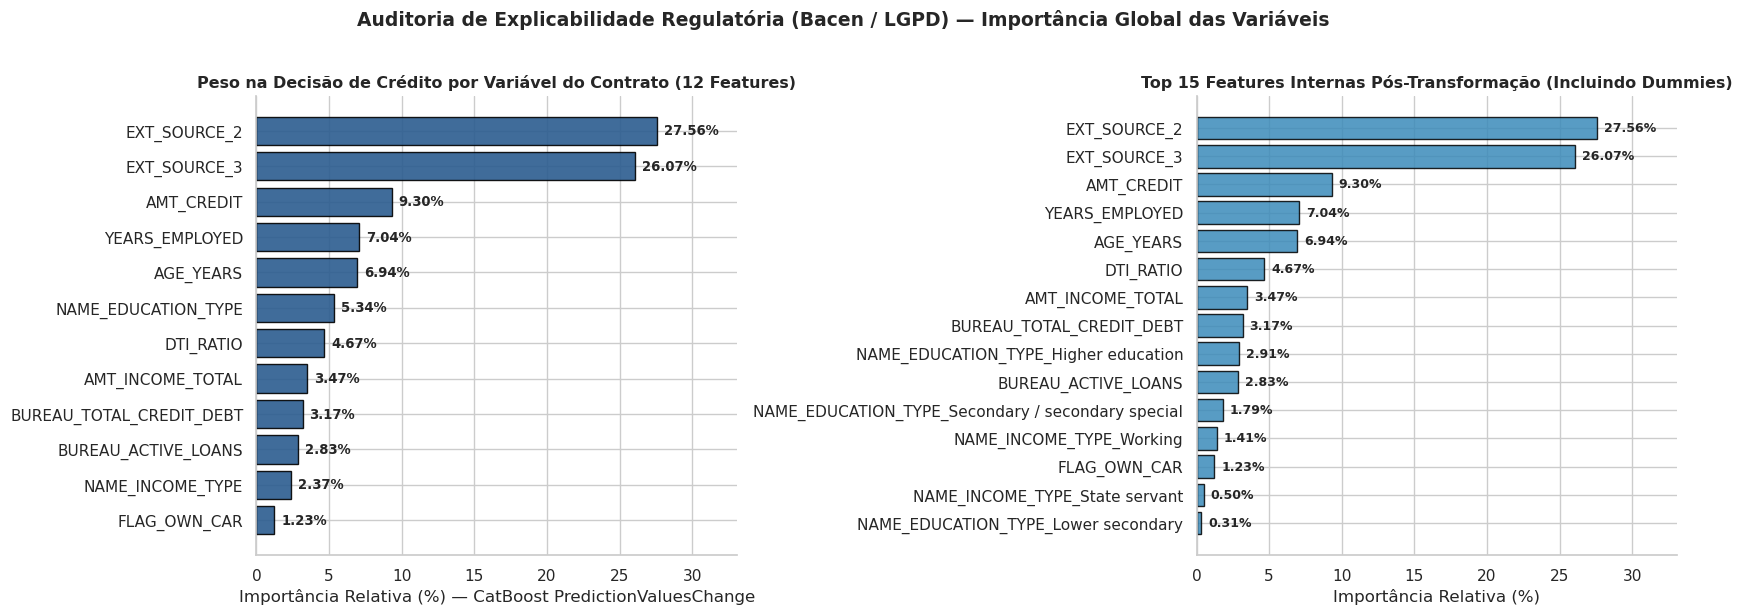

In [35]:
# EXPLICABILIDADE REGULATÓRIA: EXTRAÇÃO DA IMPORTÂNCIA DAS VARIÁVEIS (CATBOOST)
print("=" * 100)
print("ETAPA 6.1: AUDITORIA DE EXPLICABILIDADE — PESO DAS VARIÁVEIS NO MODELO CAMPEÃO")
print("=" * 100)

# Extrai os nomes das features após o ColumnTransformer (Numéricas + One-Hot Encoded)
preproc_step = best_pipeline.named_steps["preprocessor"]
clf_step = best_pipeline.named_steps["classifier"]

raw_feature_names_out = preproc_step.get_feature_names_out()
clean_feature_names = [name.replace("num__", "").replace("cat__", "") for name in raw_feature_names_out]

# Extrai a importância nativa do CatBoost (PredictionValuesChange normalizado em 100%)
importances_pct = clf_step.get_feature_importance()

df_feat_imp = pd.DataFrame({
    "Feature Transformada": clean_feature_names,
    "Importância Relativa (%)": np.round(importances_pct, 2)
}).sort_values(by="Importância Relativa (%)", ascending=False).reset_index(drop=True)

# Agrupamento também no nível das 12 variáveis originais do Contrato da API
def map_to_original_contract(feat_name):
    for orig_col in SELECTED_FEATURES:
        if feat_name.startswith(orig_col):
            return orig_col
    return feat_name

df_feat_imp["Variável do Contrato (API)"] = df_feat_imp["Feature Transformada"].apply(map_to_original_contract)
df_contract_imp = (
    df_feat_imp.groupby("Variável do Contrato (API)", as_index=False)["Importância Relativa (%)"]
    .sum()
    .sort_values(by="Importância Relativa (%)", ascending=False)
    .reset_index(drop=True)
)
df_contract_imp["Importância Acumulada (%)"] = df_contract_imp["Importância Relativa (%)"].cumsum().round(2)
df_contract_imp.index = df_contract_imp.index + 1
df_contract_imp.index.name = "Rank"

print("Peso Consolidado por Variável do Contrato da API (12 Features — 100% da Decisão):")
display(df_contract_imp)

# Gráfico de Importância das Variáveis (Top 12 Consolidado + Top 15 Transformadas)
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Subgráfico 1: Consolidado pelas 12 Variáveis do Contrato da API
df_plot_contract = df_contract_imp.sort_values(by="Importância Relativa (%)", ascending=True)
bars1 = axes[0].barh(
    df_plot_contract["Variável do Contrato (API)"],
    df_plot_contract["Importância Relativa (%)"],
    color="#2b5c8f", edgecolor="black", alpha=0.9
)
for bar in bars1:
    w = bar.get_width()
    axes[0].annotate(f"{w:.2f}%", xy=(w, bar.get_y() + bar.get_height()/2), xytext=(5, 0),
                     textcoords="offset points", ha="left", va="center", fontsize=9.5, fontweight="bold")
axes[0].set_title("Peso na Decisão de Crédito por Variável do Contrato (12 Features)", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("Importância Relativa (%) — CatBoost PredictionValuesChange")
axes[0].set_xlim(0, df_plot_contract["Importância Relativa (%)"].max() * 1.20)
sns.despine(ax=axes[0], top=True, right=True)

# Subgráfico 2: Detalhado Pós-OneHotEncoding (Top 15 Features Internas)
df_plot_detailed = df_feat_imp.head(15).sort_values(by="Importância Relativa (%)", ascending=True)
bars2 = axes[1].barh(
    df_plot_detailed["Feature Transformada"],
    df_plot_detailed["Importância Relativa (%)"],
    color="#3b8bba", edgecolor="black", alpha=0.85
)
for bar in bars2:
    w = bar.get_width()
    axes[1].annotate(f"{w:.2f}%", xy=(w, bar.get_y() + bar.get_height()/2), xytext=(5, 0),
                     textcoords="offset points", ha="left", va="center", fontsize=9, fontweight="bold")
axes[1].set_title("Top 15 Features Internas Pós-Transformação (Incluindo Dummies)", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("Importância Relativa (%)")
axes[1].set_xlim(0, df_plot_detailed["Importância Relativa (%)"].max() * 1.20)
sns.despine(ax=axes[1], top=True, right=True)

plt.suptitle("Auditoria de Explicabilidade Regulatória (Bacen / LGPD) — Importância Global das Variáveis", fontsize=13.5, fontweight="bold", y=1.02)
plt.tight_layout()

feat_imp_path = OUTPUTS_DIR / "08_feature_importance.png"
plt.savefig(feat_imp_path, dpi=300, bbox_inches="tight")
plt.show()

In [36]:
# SERIALIZAÇÃO OFICIAL DO PIPELINE (.JOBLIB) E METADADOS DE GOVERNANÇA (.JSON)

print("=" * 100)
print("ETAPA 6.2: SERIALIZAÇÃO DO PIPELINE UNIFICADO E EXPORTAÇÃO DE MÉTRICAS (MLOPS)")
print("=" * 100)

pipeline_artifact_path = MODELS_DIR / "credit_risk_pipeline.joblib"
metrics_artifact_path = MODELS_DIR / "model_metrics.json"

# Salva o pipeline completo (ColumnTransformer + CatBoostClassifier)
joblib.dump(best_pipeline, pipeline_artifact_path)
artifact_size_mb = pipeline_artifact_path.stat().st_size / (1024 * 1024)

# Métricas detalhadas da Matriz de Confusão de Teste nos dois pontos de corte
tn_ks, fp_ks, fn_ks, tp_ks = confusion_matrix(y_test, y_test_pred_ks).ravel()
tn_f1, fp_f1, fn_f1, tp_f1 = confusion_matrix(y_test, y_test_pred_f1).ravel()

model_metadata = {
    "project_name": "Credit Scoring & MLOps Pipeline (Home Credit Default Risk - MVP)",
    "model_version": "1.0.0-mvp",
    "created_at_utc": datetime.utcnow().strftime("%Y-%m-%dT%H:%M:%SZ"),
    "git_branch": "feature/model-training-evaluation",
    "champion_algorithm": "CatBoostClassifier",
    "best_hyperparameters": {
        "auto_class_weights": "Balanced",
        "depth": 4,
        "learning_rate": 0.08,
        "l2_leaf_reg": 5.0,
        "iterations": 350,
        "random_seed": 42
    },
    "data_split_summary": {
        "total_records": int(len(df_abt)),
        "train_records": int(len(X_train)),
        "validation_records": int(len(X_val)),
        "test_records": int(len(X_test)),
        "portfolio_base_bad_rate_pct": round(float(y.mean() * 100), 4),
        "imbalance_ratio": round(float((y == 0).sum() / (y == 1).sum()), 2)
    },
    "api_input_contract": {
        "total_features": len(SELECTED_FEATURES),
        "numeric_features": SELECTED_NUMERIC_FEATURES,
        "categorical_features": SELECTED_CATEGORICAL_FEATURES,
        "dropped_collinear_features": DROPPED_FEATURES
    },
    "decision_thresholds": {
        "optimal_threshold": float(optimal_threshold),
        "threshold_ks_max_protection": float(optimal_threshold),
        "threshold_f1_max_commercial": float(commercial_f1_threshold),
        "traffic_light_bands": {
            "green_auto_approve_below": float(optimal_threshold),
            "yellow_manual_review_between": [float(optimal_threshold), float(commercial_f1_threshold)],
            "red_auto_reject_above_or_equal": float(commercial_f1_threshold)
        }
    },
    "validation_metrics": {
        "roc_auc": round(float(roc_auc_score(y_val, y_val_proba)), 4),
        "ks_statistic_pct": round(float(ks_val), 2),
        "recall_at_ks_threshold": round(float(recall_score(y_val, (y_val_proba >= optimal_threshold).astype(int))), 4),
        "f1_at_commercial_threshold": round(float(best_f1_row["f1"]), 4)
    },
    "test_holdout_metrics": {
        "roc_auc": round(float(auc_test), 4),
        "roc_auc_ci95_bootstrap": [round(float(auc_ci_low), 4), round(float(auc_ci_high), 4)],
        "ks_statistic_pct": round(float(ks_test), 2),
        "policy_ks_protection_0_5027": {
            "threshold": float(optimal_threshold),
            "approval_rate_pct": round(float((tn_ks + fn_ks) / len(y_test) * 100), 2),
            "approved_portfolio_bad_rate_pct": round(float(fn_ks / (tn_ks + fn_ks) * 100), 2),
            "relative_risk_reduction_pct": round(float(((fn_ks / (tn_ks + fn_ks)) - p_control) / p_control * 100), 2),
            "recall_bads_captured_pct": round(float(tp_ks / (tp_ks + fn_ks) * 100), 2),
            "precision_rejected_pct": round(float(tp_ks / (tp_ks + fp_ks) * 100), 2),
            "f1_score": round(float(f1_score(y_test, y_test_pred_ks)), 4),
            "f2_score": round(float(fbeta_score(y_test, y_test_pred_ks, beta=2.0)), 4),
            "confusion_matrix": {"TN": int(tn_ks), "FP": int(fp_ks), "FN": int(fn_ks), "TP": int(tp_ks)}
        },
        "policy_f1_commercial_0_6400": {
            "threshold": float(commercial_f1_threshold),
            "approval_rate_pct": round(float((tn_f1 + fn_f1) / len(y_test) * 100), 2),
            "approved_portfolio_bad_rate_pct": round(float(fn_f1 / (tn_f1 + fn_f1) * 100), 2),
            "relative_risk_reduction_pct": round(float(((fn_f1 / (tn_f1 + fn_f1)) - p_control) / p_control * 100), 2),
            "recall_bads_captured_pct": round(float(tp_f1 / (tp_f1 + fn_f1) * 100), 2),
            "precision_rejected_pct": round(float(tp_f1 / (tp_f1 + fp_f1) * 100), 2),
            "f1_score": round(float(f1_score(y_test, y_test_pred_f1)), 4),
            "f2_score": round(float(fbeta_score(y_test, y_test_pred_f1, beta=2.0)), 4),
            "confusion_matrix": {"TN": int(tn_f1), "FP": int(fp_f1), "FN": int(fn_f1), "TP": int(tp_f1)}
        }
    },
    "ab_hypothesis_testing_test_set": {
        "z_test_bad_rate_reduction": {
            "z_statistic": round(float(z_stat), 4),
            "p_value": float(f"{p_val_z:.4e}"),
            "statistically_significant": bool(p_val_z < 0.0001)
        },
        "chi2_independence_and_odds_ratio": {
            "chi2_statistic": round(float(chi2_stat), 2),
            "odds_ratio_rejected_vs_approved": round(float(odds_ratio), 2),
            "statistically_significant": bool(p_val_chi2 < 0.0001)
        }
    },
    "feature_importance_contract_pct": {
        row["Variável do Contrato (API)"]: float(row["Importância Relativa (%)"])
        for _, row in df_contract_imp.iterrows()
    }
}

with open(metrics_artifact_path, "w", encoding="utf-8") as f:
    json.dump(model_metadata, f, indent=4, ensure_ascii=False)

print(f"[SUCESSO] Pipeline serializado salvo em : {pipeline_artifact_path} ({artifact_size_mb:.2f} MB)")
print(f"[SUCESSO] Metadados e Métricas salvos em: {metrics_artifact_path}\n")

ETAPA 6.2: SERIALIZAÇÃO DO PIPELINE UNIFICADO E EXPORTAÇÃO DE MÉTRICAS (MLOPS)
[SUCESSO] Pipeline serializado salvo em : /home/jean/Área de trabalho/Projeto Risco De Crédito/Home-Credit-Default-Risk/models/credit_risk_pipeline.joblib (0.12 MB)
[SUCESSO] Metadados e Métricas salvos em: /home/jean/Área de trabalho/Projeto Risco De Crédito/Home-Credit-Default-Risk/models/model_metrics.json



In [37]:
# TESTE DE INTEGRIDADE E INFERÊNCIA UNITÁRIA (SMOKE TEST P/ API FASTAPI)
print("=" * 100)
print("ETAPA 6.3: TESTE DE INTEGRIDADE (COLD LOAD DO .JOBLIB E SIMULAÇÃO DE PAYLOAD DA API)")
print("=" * 100)

# Carregamento a frio dos artefatos do disco exatamente como a API FastAPI fará no startup
loaded_pipeline = joblib.load(pipeline_artifact_path)
with open(metrics_artifact_path, "r", encoding="utf-8") as f:
    loaded_meta = json.load(f)

th_ks_loaded = loaded_meta["decision_thresholds"]["threshold_ks_max_protection"]
th_f1_loaded = loaded_meta["decision_thresholds"]["threshold_f1_max_commercial"]

# Seleciona 3 perfis reais da base de Teste (1 Baixo Risco, 1 Zona Cinzenta, 1 Alto Risco) + 1 Payload com Nulos
idx_low_risk = y_test_proba.argmin()
idx_high_risk = y_test_proba.argmax()
idx_gray_zone = np.where((y_test_proba >= th_ks_loaded) & (y_test_proba < th_f1_loaded))[0][0]

sample_indices = [idx_low_risk, idx_gray_zone, idx_high_risk]
smoke_test_records = []

for label_perfil, pos_idx in zip(["Cliente Perfil A (Baixo Risco)", "Cliente Perfil B (Zona Cinzenta)", "Cliente Perfil C (Alto Risco)"], sample_indices):
    # Extrai 1 único registro como dicionário (simulando um JSON recebido via POST /predict na FastAPI)
    single_payload_dict = X_test.iloc[pos_idx].to_dict()
    real_target = int(y_test.iloc[pos_idx])
    
    # Converte o dicionário único em DataFrame de 1 linha e executa a inferência pelo artefato carregado
    df_single = pd.DataFrame([single_payload_dict])
    prob_default = float(loaded_pipeline.predict_proba(df_single)[0, 1])
    
    # Verifica consistência matemática exata com a predição em memória antes de salvar
    assert np.isclose(prob_default, y_test_proba[pos_idx], atol=1e-6), "Erro de integridade na serialização!"
    
    # Classificação nas 3 faixas de negócio e binária
    if prob_default < th_ks_loaded:
        faixa_decisao = "🟢 APROVADO_AUTOMATICO"
    elif prob_default < th_f1_loaded:
        faixa_decisao = "🟡 ANALISE_CONDICIONAL (Zona Cinzenta)"
    else:
        faixa_decisao = "🔴 REPROVADO_AUTOMATICO"
        
    smoke_test_records.append({
        "Caso de Teste (API)": label_perfil,
        "Score P(Default)": round(prob_default, 4),
        "Predição Binária (th=0.5027)": int(prob_default >= th_ks_loaded),
        "Decisão da Política (3 Faixas)": faixa_decisao,
        "Status Real (Target)": f"{real_target} ({'Inadimplente' if real_target==1 else 'Bom Pagador'})",
        "EXT_SOURCE_2": round(single_payload_dict["EXT_SOURCE_2"], 3),
        "EXT_SOURCE_3": round(single_payload_dict["EXT_SOURCE_3"], 3) if pd.notna(single_payload_dict["EXT_SOURCE_3"]) else "NULL (Imputado)",
        "DTI_RATIO": round(single_payload_dict["DTI_RATIO"], 3)
    })

# Teste adicional de resiliência: Cliente com Nulos Legítimos e Categoria Inédita (Cold Start)
stress_payload = X_test.iloc[0].to_dict()
stress_payload["EXT_SOURCE_3"] = np.nan
stress_payload["YEARS_EMPLOYED"] = np.nan
stress_payload["NAME_INCOME_TYPE"] = "Autonomous_Crypto_Freelancer"  # Categoria nunca vista no treino!

df_stress = pd.DataFrame([stress_payload])
prob_stress = float(loaded_pipeline.predict_proba(df_stress)[0, 1])
smoke_test_records.append({
    "Caso de Teste (API)": "Teste Stress (Nulos + Categoria Inédita)",
    "Score P(Default)": round(prob_stress, 4),
    "Predição Binária (th=0.5027)": int(prob_stress >= th_ks_loaded),
    "Decisão da Política (3 Faixas)": "🟢 APROVADO_AUTOMATICO" if prob_stress < th_ks_loaded else ("🟡 ANALISE_CONDICIONAL" if prob_stress < th_f1_loaded else "🔴 REPROVADO_AUTOMATICO"),
    "Status Real (Target)": "Simulado (Stress Test)",
    "EXT_SOURCE_2": round(stress_payload["EXT_SOURCE_2"], 3),
    "EXT_SOURCE_3": "NULL (Imputado OK)",
    "DTI_RATIO": round(stress_payload["DTI_RATIO"], 3)
})

df_smoke_test = pd.DataFrame(smoke_test_records)
display(df_smoke_test)

# Verificação final
print("\n" + "=" * 100)
print("CHECKLIST FINAL DE ARTEFATOS GERADOS NO DIA 2 (PRONTOS PARA O GIT COMMIT)")
print("=" * 100)
for folder in [OUTPUTS_DIR, MODELS_DIR]:
    print(f"\n Diretório: {folder}")
    for file_p in sorted(folder.glob("*")):
        size_kb = file_p.stat().st_size / 1024
        print(f"   {file_p.name:<42} | Tamanho: {size_kb:>8.1f} KB")

ETAPA 6.3: TESTE DE INTEGRIDADE (COLD LOAD DO .JOBLIB E SIMULAÇÃO DE PAYLOAD DA API)


,Caso de Teste (API),Score P(Default),Predição Binária (th=0.5027),Decisão da Política (3 Faixas),Status Real (Target),EXT_SOURCE_2,EXT_SOURCE_3,DTI_RATIO
0,Cliente Perfil A (Baixo Risco),0.0135,0,🟢 APROVADO_AUTOMATICO,0 (Bom Pagador),0.7430,0.8030,0.2260
1,Cliente Perfil B (Zona Cinzenta),0.5499,1,🟡 ANALISE_CONDICIONAL (Zona Cinzenta),0 (Bom Pagador),0.6330,NULL (Imputado),0.1080
2,Cliente Perfil C (Alto Risco),0.9594,1,🔴 REPROVADO_AUTOMATICO,1 (Inadimplente),0.0140,0.0830,0.2150
3,Teste Stress (Nulos + Categoria Inédita),0.2095,0,🟢 APROVADO_AUTOMATICO,Simulado (Stress Test),0.6680,NULL (Imputado OK),0.1890



CHECKLIST FINAL DE ARTEFATOS GERADOS NO DIA 2 (PRONTOS PARA O GIT COMMIT)

 Diretório: /home/jean/Área de trabalho/Projeto Risco De Crédito/Home-Credit-Default-Risk/outputs
   01_distribicao_target.png                  | Tamanho:    148.3 KB
   02_distribuicao_numerica_vs_target.png     | Tamanho:    888.2 KB
   03_categórico_bad_rates.png                | Tamanho:    274.5 KB
   04_matriz_correlacao.png                   | Tamanho:    601.8 KB
   05_matrizes_confusao_triagem.png           | Tamanho:    325.6 KB
   06_avaliacao_risco_de_credito.png          | Tamanho:   1027.0 KB
   07_teste_ab_impacto_negocio.png            | Tamanho:    395.7 KB
   08_feature_importance.png                  | Tamanho:    530.9 KB

 Diretório: /home/jean/Área de trabalho/Projeto Risco De Crédito/Home-Credit-Default-Risk/models
   .gitkeep                                   | Tamanho:      0.0 KB
   credit_risk_pipeline.joblib                | Tamanho:    126.5 KB
   model_metrics.json                 

---

# Conclusão e Prontidão para MLOps 

A etapa de Análise Exploratória de Dados (EDA), Seleção de Features, Modelagem Preditiva, Validação Estatística (Teste A/B) e Serialização foi concluída:

1. **Explicabilidade Auditável (5 Cs do Crédito):** A extração de importância nativa do `CatBoostClassifier` comprovou que todas as **12 variáveis do contrato da API** contribuem ativamente para a decisão:
   - **Caráter (Birôs Externos):** `EXT_SOURCE_2` (**27,56%**) e `EXT_SOURCE_3` (**26,07%**) respondem por **53,63%** do poder decisório.
   - **Condições e Capacidade:** `AMT_CREDIT` (**9,30%**), `DTI_RATIO` (**4,67%**) e `AMT_INCOME_TOTAL` (**3,47%**) somam **17,44%**, demonstrando a captura de interações não-lineares de esforço financeiro.
   - **Estabilidade, Maturidade e Alavancagem:** `YEARS_EMPLOYED` (**7,04%**), `AGE_YEARS` (**6,94%**), `NAME_EDUCATION_TYPE` (**5,34%**), `BUREAU_TOTAL_CREDIT_DEBT` (**3,17%**), `BUREAU_ACTIVE_LOANS` (**2,83%**), `NAME_INCOME_TYPE` (**2,37%**) e `FLAG_OWN_CAR` (**1,23%**) consolidam os **28,92%** restantes.
2. **Artefatos de Produção Gerados e Validados:**
   - `models/credit_risk_pipeline.joblib` (**0,12 MB**): Pipeline único (`ColumnTransformer` + `CatBoostClassifier`) validado contra *Data Leakage*, *Cold Start* categórico e valores ausentes.
   - `models/model_metrics.json`: Contrato formal contendo hiperparâmetros, métricas de Holdout (**ROC-AUC = 0.7353**, **KS = 34,79%**), resultados do Teste A/B ($p < 0.0001$) e os limiares da régua de decisão em 3 faixas (`0.5027` e `0.6400`).
   - `outputs/*.png`: 8 painéis gráficos de alta resolução (300 DPI) documentando toda a trilha científica do projeto.

**Próximo Passo :** Construção do microsserviço de inferência em **FastAPI**, validação de contrato com **Pydantic**, testes automatizados com **Pytest** e empacotamento em container **Docker**.